# 04 Estudos de caso do fatorial $2^2r$

## Latência de API, energia em IoT e tempo de treinamento

Os três casos relacionam uma resposta de desempenho a dois fatores controláveis. Cada combinação possui oito replicações independentes. Os dados são artificiais e são gerados nas próprias células por um modelo com erro normal.

A unidade experimental é a sessão completa. Medições internas de uma sessão produzem sua resposta e não são contadas como replicações adicionais. A sequência simulada de execução fica guardada no vetor `ordem`.


In [ ]:
from pathlib import Path
from itertools import combinations, product
import base64
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Markdown

NOME_NOTEBOOK = '04_estudos_de_caso_22r'
CONFIANCA = CONFIDENCE_LEVEL = 0.90
ALPHA = 1-CONFIANCA
BASE = Path.cwd()
if BASE.name == 'notebooks':
    BASE = BASE.parent
FIGURAS = BASE/'figuras'/NOME_NOTEBOOK
TABELAS = BASE/'tabelas'/NOME_NOTEBOOK
FIGURAS.mkdir(parents=True,exist_ok=True)
TABELAS.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({
    'font.family':'serif','font.serif':['STIXGeneral','DejaVu Serif'],
    'mathtext.fontset':'stix','font.size':11,'axes.labelsize':11,
    'xtick.labelsize':9,'ytick.labelsize':9,'legend.fontsize':9,
    'figure.dpi':130,'figure.facecolor':'white','axes.facecolor':'white',
    'axes.spines.top':False,'axes.spines.right':False,'axes.grid':False,
    'axes.linewidth':.8,'lines.linewidth':1.4,'lines.markersize':4.5,
    'pdf.fonttype':42,'ps.fonttype':42,'savefig.facecolor':'white'})
AZUL='#24577A'
LARANJA='#B76532'
VERDE='#44735B'
CINZA='#707070'
CORES=[AZUL,LARANJA,VERDE,CINZA]
pd.set_option('display.max_columns',14)
pd.set_option('display.float_format',lambda x:f'{x:.5g}')

def salvar_figura(fig,nome):
    if any(ax.get_title() or ax.get_title(loc='left') or ax.get_title(loc='right') for ax in fig.axes):
        raise ValueError('A identificação pertence à legenda externa da figura')
    if getattr(fig,'_suptitle',None) is not None:
        raise ValueError('A identificação pertence ao texto')
    w,h=fig.get_size_inches()
    if w>10 or h>10 or w<3 or h<2:
        raise ValueError('Dimensões físicas inadequadas')
    pdf=FIGURAS/f'{nome}.pdf'
    png=FIGURAS/f'{nome}.png'
    fig.savefig(pdf,format='pdf',dpi=600)
    fig.savefig(png,format='png',dpi=180)
    largura=1000 if len(fig.axes)>1 else 820
    display({'image/png':base64.b64encode(png.read_bytes()).decode('ascii')},raw=True,
        metadata={'image/png':{'width':largura,'height':round(largura*h/w)},
                  'fatorial_pdf':str(pdf.relative_to(BASE)),
                  'largura_polegadas':float(w),'altura_polegadas':float(h)})
    plt.close(fig)

def salvar_tabela(tabela,nome,indice=False,colunas_p=None):
    tabela.to_csv(TABELAS/f'{nome}.csv',index=indice)
    copia=tabela.copy()
    if colunas_p:
        for col in colunas_p:
            copia[col]=copia[col].map(lambda p:'' if pd.isna(p) else formatar_p(p))
    display(copia)

def formatar_p(p):
    return '< 1e-300' if p<=0 else f'{p:.4g}'

def decisao_teste(nome,p,contra,sem_evidencia):
    if not np.isfinite(p):
        display(Markdown(f'**{nome}**\n\nO valor-p não está definido para estes dados. A decisão depende do gráfico e das condições do diagnóstico.'))
        return
    if p<=ALPHA:
        texto=f'É significativo porque o valor-p {formatar_p(p)} é menor ou igual a {ALPHA:.2f}. {contra}'
    else:
        texto=f'Não é significativo porque o valor-p {formatar_p(p)} é maior que {ALPHA:.2f}. {sem_evidencia}'
    display(Markdown(f'**{nome}**\n\n{texto}'))

def matriz_sinais(k):
    if not isinstance(k,(int,np.integer)) or not 1<=k<=8:
        raise ValueError('Use entre um e oito fatores no fatorial completo')
    g=2**k
    niveis=2*((np.arange(g)[:,None]>>np.arange(k))&1)-1
    letras=[chr(65+i) for i in range(k)]
    termos=[]
    colunas=[]
    for mascara in range(g):
        ids=[j for j in range(k) if mascara&(1<<j)]
        termos.append(''.join(letras[j] for j in ids) if ids else '0')
        colunas.append(np.prod(niveis[:,ids],axis=1) if ids else np.ones(g))
    return niveis,np.column_stack(colunas),termos

def ajustar(response):
    response=np.asarray(response,dtype=float)
    if response.ndim!=2 or response.shape[0]<2:
        raise ValueError('Use uma matriz com combinações nas linhas e replicações nas colunas')
    g,r=response.shape
    k=int(np.log2(g))
    if 2**k!=g or r<2 or not np.isfinite(response).all():
        raise ValueError('O desenho completo exige 2**k combinações e pelo menos duas replicações finitas')
    niveis,Xc,termos=matriz_sinais(k)
    N=response.size
    nu=g*(r-1)
    medias=response.mean(axis=1)
    q=Xc.T@medias/g
    X=np.repeat(Xc,r,axis=0)
    y=response.ravel()
    ajustados=X@q
    residuos=y-ajustados
    SSE=float(residuos@residuos)
    SST=float(np.sum((y-y.mean())**2))
    MSE=SSE/nu
    if MSE<=np.finfo(float).eps*max(1,float(np.mean(y*y))):
        raise ValueError('O erro puro é nulo ou numericamente desprezível')
    SS=N*q[1:]**2
    se=np.sqrt(MSE)
    sq=se/np.sqrt(N)
    t=q[1:]/sq
    pval=2*stats.t.sf(np.abs(t),nu)
    crit=stats.t.ppf(1-ALPHA/2,nu)
    efeitos=pd.DataFrame({'Termo':termos[1:],'q':q[1:],'EP de q':sq,
        'IC inferior':q[1:]-crit*sq,'IC superior':q[1:]+crit*sq,
        'Efeito 2q':2*q[1:],'t':t,'Valor-p':pval,
        'Significativo':np.where(pval<=ALPHA,'Sim','Não')})
    anova=pd.DataFrame({'Fonte':termos[1:]+['Erro','Total'],
        'SS':np.r_[SS,SSE,SST],'gl':np.r_[np.ones(g-1,dtype=int),nu,N-1],
        'MS':np.r_[SS,MSE,np.nan],'F':np.r_[SS/MSE,np.nan,np.nan],
        'Valor-p':np.r_[pval,np.nan,np.nan]})
    F_global=float(np.sum(SS)/(g-1)/MSE)
    p_global=float(stats.f.sf(F_global,g-1,nu))
    assert np.isclose(SST,SS.sum()+SSE)
    assert np.allclose(Xc.T@Xc,g*np.eye(g))
    assert np.allclose(SS/MSE,t*t)
    return dict(response=response,k=k,g=g,r=r,N=N,nu=nu,Xc=Xc,X=X,niveis=niveis,
        termos=termos,q=q,y=y,medias=medias,ajustados=ajustados,residuos=residuos,
        SSE=SSE,SST=SST,SS=SS,MSE=MSE,se=se,sq=sq,anova=anova,efeitos=efeitos,
        F_global=F_global,p_global=p_global)

def modelo_escrito(res,nomes=None,resposta='y'):
    partes=[f'{res["q"][0]:.4g}']
    for termo,valor in zip(res['termos'][1:],res['q'][1:]):
        produto=''.join('x_{'+letra+'}' for letra in termo)
        partes.append((' + ' if valor>=0 else ' - ')+f'{abs(valor):.4g}'+produto)
    display(Markdown('$$\\widehat{'+resposta+'}='+''.join(partes)+'.$$'))

def mostrar_resultados(res):
    salvar_tabela(res['efeitos'],'efeitos_ic_testes',colunas_p=['Valor-p'])
    for termo,p in zip(res['termos'][1:],res['efeitos']['Valor-p']):
        decisao_teste(f'Efeito q{termo}',p,
            f'Há evidência de que q{termo} difere de zero nas condições do modelo.',
            f'Não há evidência suficiente de que q{termo} difere de zero. Isso não demonstra ausência de efeito.')

def mostrar_anova(res):
    salvar_tabela(res['anova'],'anova',colunas_p=['Valor-p'])
    tabela=pd.DataFrame([{'F global':res['F_global'],'gl numerador':res['g']-1,
        'gl denominador':res['nu'],'Valor-p':res['p_global']}])
    salvar_tabela(tabela,'F_global',colunas_p=['Valor-p'])
    decisao_teste('Teste F global',res['p_global'],
        'Há evidência de que pelo menos um termo do modelo difere de zero.',
        'Não há evidência suficiente de diferença entre as médias das combinações.')

def graficos_efeitos(res,prefixo):
    fig,ax=plt.subplots(figsize=(5,3),layout='constrained')
    ids=np.arange(res['g']-1)
    margem=stats.t.ppf(1-ALPHA/2,res['nu'])*res['sq']
    ax.errorbar(res['q'][1:],ids,xerr=margem,fmt='o',capsize=3,color=AZUL)
    ax.axvline(0,color=CINZA,lw=.8)
    ax.set_yticks(ids,['q'+t for t in res['termos'][1:]])
    ax.set_xlabel('Coeficiente q e IC de 90% ('+res.get('unidade','u.r.')+')')
    ax.set_ylabel('Termo')
    salvar_figura(fig,prefixo+'_efeitos')

def grafico_variacao(res,prefixo):
    nomes=res['termos'][1:]+['Erro']
    percent=100*np.r_[res['SS'],res['SSE']]/res['SST']
    tabela=pd.DataFrame({'Fonte':nomes,'SS':np.r_[res['SS'],res['SSE']],
                        'Variação alocada (%)':percent})
    salvar_tabela(tabela,prefixo+'_variacao')
    fig,ax=plt.subplots(figsize=(5,3),layout='constrained')
    ordem=np.argsort(percent)
    ax.barh(np.asarray(nomes)[ordem],percent[ordem],color=[CINZA if nomes[i]=='Erro' else AZUL for i in ordem])
    ax.set_xlabel('Variação total alocada (%)')
    ax.set_ylabel('Fonte')
    salvar_figura(fig,prefixo+'_variacao')

def graficos_niveis(res,nomes,niveis_reais,prefixo,com_ic=True):
    k=res['k']
    cols=min(2,k)
    rows=int(np.ceil(k/cols))
    tamanho=(5,3) if rows==1 else (5,5)
    fig,axes=plt.subplots(rows,cols,figsize=tamanho,squeeze=False,layout='constrained')
    ep=res['se']/np.sqrt(res['N']/2)
    margem=stats.t.ppf(1-ALPHA/2,res['nu'])*ep
    for j,ax in enumerate(axes.ravel()):
        if j>=k:
            ax.set_visible(False)
            continue
        vals=[res['medias'][res['niveis'][:,j]==a].mean() for a in [-1,1]]
        if com_ic:ax.errorbar([0,1],vals,yerr=margem,fmt='o-',capsize=3,color=AZUL)
        else:ax.plot([0,1],vals,'o-',color=AZUL)
        ax.set_xticks([0,1],niveis_reais[j])
        ax.set_xlabel(nomes[j])
        ax.set_ylabel('Média ('+res.get('unidade','u.r.')+')'+(' e IC de 90%' if com_ic else ''))
        ax.text(.01,1.025,f'({chr(97+j)})',transform=ax.transAxes,ha='left',va='bottom')
        ax.margins(x=.15)
    salvar_figura(fig,prefixo+'_niveis')

def graficos_interacoes(res,nomes,niveis_reais,prefixo,com_ic=True):
    k=res['k']
    paineis=[]
    if k==1:return
    for a,b in combinations(range(k),2):
        outros=[j for j in range(k) if j not in [a,b]]
        for condicao in product([-1,1],repeat=len(outros)):
            paineis.append((a,b,outros,condicao))
    if k==2:paineis.append((1,0,[],()))
    margem=stats.t.ppf(1-ALPHA/2,res['nu'])*res['se']/np.sqrt(res['r'])
    for inicio in range(0,len(paineis),6):
        bloco=paineis[inicio:inicio+6]
        cols=2 if len(bloco)<=4 else 3
        rows=int(np.ceil(len(bloco)/cols))
        tamanho=(5,3) if rows==1 else ((5,5) if cols==2 else (7,5))
        fig,axes=plt.subplots(rows,cols,figsize=tamanho,squeeze=False,layout='constrained')
        mapa=[]
        for t,ax in enumerate(axes.ravel()):
            if t>=len(bloco):
                ax.set_visible(False)
                continue
            a,b,outros,condicao=bloco[t]
            cond=np.ones(res['g'],dtype=bool)
            for j,v in zip(outros,condicao):cond&=res['niveis'][:,j]==v
            for nivel,cor in [(-1,AZUL),(1,LARANJA)]:
                ys=[res['medias'][cond&(res['niveis'][:,a]==x)&(res['niveis'][:,b]==nivel)].mean() for x in [-1,1]]
                rotulo=niveis_reais[b][0 if nivel==-1 else 1]
                if com_ic:ax.errorbar([0,1],ys,yerr=margem,fmt='o-',capsize=2.5,label=rotulo,color=cor)
                else:ax.plot([0,1],ys,'o-',label=rotulo,color=cor)
            letra=chr(97+t)
            ax.text(.01,1.025,f'({letra})',transform=ax.transAxes,ha='left',va='bottom')
            ax.set_xticks([0,1],niveis_reais[a])
            ax.set_xlabel(nomes[a])
            ax.set_ylabel('Média ('+res.get('unidade','u.r.')+')')
            ax.margins(x=.15,y=.16)
            ax.legend(frameon=False,title=nomes[b],fontsize=8,title_fontsize=9)
            fixos=', '.join(f'{nomes[j]} em {niveis_reais[j][0 if v==-1 else 1]}' for j,v in zip(outros,condicao))
            mapa.append(f'({letra}) {nomes[a]} e {nomes[b]}'+(', '+fixos if fixos else ''))
        display(Markdown('Painéis do gráfico. '+'. '.join(mapa)+'.'))
        salvar_figura(fig,prefixo+f'_interacoes_{inicio//6+1}')

def grid_residuos(res,ordem,prefixo):
    ordem=np.asarray(ordem,dtype=int)
    if not np.array_equal(np.sort(ordem),np.arange(res['N'])):
        raise ValueError('A ordem deve conter cada índice de observação uma vez')
    fig,axes=plt.subplots(2,2,figsize=(5,5),layout='constrained')
    ax=axes[0,0]
    ax.scatter(res['ajustados'],res['residuos'],s=17,color=AZUL)
    ax.axhline(0,color=CINZA,lw=.7)
    ax.set_xlabel('Resposta ajustada ('+res.get('unidade','u.r.')+')')
    ax.set_ylabel('Resíduo ('+res.get('unidade','u.r.')+')')
    ax=axes[0,1]
    for i in range(res['g']):
        ax.scatter(i+1+np.linspace(-.13,.13,res['r']),res['residuos'].reshape(res['g'],res['r'])[i],s=17,color=AZUL)
    ax.axhline(0,color=CINZA,lw=.7)
    ax.set_xlabel('Combinação')
    ax.set_ylabel('Resíduo ('+res.get('unidade','u.r.')+')')
    ax.set_xticks(np.arange(1,res['g']+1))
    ax=axes[1,0]
    quantis,observados=stats.probplot(res['residuos']/(res['se']*np.sqrt(1-1/res['r'])),dist='norm',fit=False)
    ax.scatter(quantis,observados,s=17,color=AZUL)
    ax.plot([min(quantis),max(quantis)],[min(quantis),max(quantis)],color=CINZA,lw=.8)
    ax.set_xlabel('Quantil normal teórico')
    ax.set_ylabel('Resíduo em\nescala comparável')
    ax=axes[1,1]
    ax.plot(np.arange(1,res['N']+1),res['residuos'][ordem],'o-',markersize=3,lw=.8,color=AZUL)
    ax.axhline(0,color=CINZA,lw=.7)
    ax.set_xlabel('Ordem de execução')
    ax.set_ylabel('Resíduo ('+res.get('unidade','u.r.')+')')
    for i,ax in enumerate(axes.ravel()):
        ax.text(.01,1.025,f'({chr(97+i)})',transform=ax.transAxes,ha='left',va='bottom')
    salvar_figura(fig,prefixo+'_residuos')

def _estatistica_ks(amostras):
    amostras=np.atleast_2d(amostras)
    n=amostras.shape[1]
    z=(amostras-amostras.mean(axis=1,keepdims=True))/amostras.std(axis=1,ddof=1,keepdims=True)
    F=stats.norm.cdf(np.sort(z,axis=1))
    return np.maximum(np.max(np.arange(1,n+1)/n-F,axis=1),
                      np.max(F-np.arange(n)/n,axis=1))

def diagnosticos(res,ordem,prefixo):
    ordem=np.asarray(ordem,dtype=int)
    if not np.array_equal(np.sort(ordem),np.arange(res['N'])):
        raise ValueError('A ordem deve ser uma permutação dos índices das observações')
    if res['r']==2:
        W_variancia,p_variancia=np.nan,np.nan
    else:
        W_variancia,p_variancia=stats.levene(*res['response'],center='median')
    e=res['residuos']
    W=float(stats.shapiro(e).statistic)
    D=float(_estatistica_ks(e)[0])
    DW=float(np.sum(np.diff(e[ordem])**2)/np.sum(e*e))
    B=4999
    rng=np.random.default_rng(180042)
    erros=rng.normal(size=(B,res['g'],res['r']))
    simulados=(erros-erros.mean(axis=2,keepdims=True)).reshape(B,res['N'])
    Ws=stats.shapiro(simulados,axis=1).statistic
    Ds=_estatistica_ks(simulados)
    DWs=np.sum(np.diff(simulados[:,ordem],axis=1)**2,axis=1)/np.sum(simulados*simulados,axis=1)
    p_W=(1+np.count_nonzero(Ws<=W))/(B+1)
    p_D=(1+np.count_nonzero(Ds>=D))/(B+1)
    p_DW=min(1,2*min((1+np.count_nonzero(DWs<=DW))/(B+1),
                     (1+np.count_nonzero(DWs>=DW))/(B+1)))
    tabela=pd.DataFrame({'Diagnóstico':['Brown e Forsythe','Shapiro e Wilk','Kolmogorov e Smirnov','Durbin e Watson'],
        'Estatística':[W_variancia,W,D,DW],
        'Valor-p':[p_variancia,p_W,p_D,p_DW],
        'Referência':['F aproximada','Normal no mesmo desenho','Normal no mesmo desenho','Normal independente no mesmo desenho']})
    salvar_tabela(tabela,prefixo+'_diagnosticos',colunas_p=['Valor-p'])
    if res['r']==2:
        display(Markdown('Com duas replicações por combinação, os dois desvios absolutos em relação à mediana são iguais. O teste de Brown e Forsythe fica degenerado. A comparação de dispersões deve usar os gráficos e exige mais replicações para esse teste.'))
    decisao_teste('Homocedasticidade',p_variancia,
        'Há evidência contra a igualdade das variâncias.',
        'Não há evidência suficiente contra a igualdade das variâncias.')
    for nome,p in [('Shapiro e Wilk',p_W),('Kolmogorov e Smirnov',p_D)]:
        decisao_teste(nome,p,'Há evidência contra a normalidade dos erros sob a referência adotada.',
            'Não há evidência suficiente contra a normalidade sob a referência adotada.')
    decisao_teste('Durbin e Watson',p_DW,
        'Há evidência de dependência serial na comparação com a referência independente.',
        'Não há evidência suficiente de dependência serial nessa comparação. O protocolo continua necessário.')
    return tabela

def grid_padroes(prefixo):
    rng=np.random.default_rng(180043)
    n=80
    x=np.linspace(-1,1,n)
    iid=rng.normal(0,1,n)
    pos=np.zeros(n)
    neg=np.zeros(n)
    for i in range(1,n):
        pos[i]=.83*pos[i-1]+rng.normal(0,.6)
        neg[i]=-.83*neg[i-1]+rng.normal(0,.6)
    padroes=[iid,pos,neg,2*np.sin(np.linspace(0,5*np.pi,n))+rng.normal(0,.3,n),
        rng.normal(0,np.linspace(.2,2,n)),3*(x*x-x.dot(x)/n)+rng.normal(0,.3,n)]
    fig,axes=plt.subplots(2,3,figsize=(7,5),layout='constrained')
    for i,(ax,e) in enumerate(zip(axes.ravel(),padroes)):
        eixo=np.arange(1,n+1) if i<4 else x
        if i<4:ax.plot(eixo,e,'o-',markersize=2,lw=.7,color=AZUL)
        else:ax.scatter(eixo,e,s=11,color=AZUL)
        ax.axhline(0,color=CINZA,lw=.7)
        ax.set_xlabel('Ordem' if i<4 else 'Valor ajustado')
        ax.set_ylabel('Resíduo ilustrativo')
        ax.text(.01,1.025,f'({chr(97+i)})',transform=ax.transAxes,va='bottom')
    salvar_figura(fig,prefixo+'_padroes')

def graficos_comparacao(resultados,rotulos,prefixo):
    fig,axes=plt.subplots(1,len(resultados),figsize=(5,3) if len(resultados)<=2 else (7,3),
                          squeeze=False,layout='constrained')
    for i,(res,rotulo) in enumerate(zip(resultados,rotulos)):
        ax=axes[0,i]
        margem=stats.t.ppf(1-ALPHA/2,res['nu'])*res['sq']
        ax.errorbar(res['q'][1:],np.arange(res['g']-1),xerr=margem,fmt='o',capsize=3,color=CORES[i%4])
        ax.axvline(0,color=CINZA,lw=.7)
        ax.set_yticks(np.arange(res['g']-1),['q'+t for t in res['termos'][1:]])
        ax.set_xlabel('q e IC de 90% ('+res.get('unidade','u.r.')+')')
        ax.set_ylabel(rotulo)
    salvar_figura(fig,prefixo+'_comparacao')

from pathlib import Path
import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats


def _dados_combinacoes(res, nomes, niveis_reais):
    response = np.asarray(res['response'], dtype=float)
    if response.ndim != 2 or response.shape[0] < 2 or response.shape[1] < 2 or not np.isfinite(response).all():
        raise ValueError('Use respostas finitas com ao menos duas replicações por combinação')
    g, r = response.shape
    k = int(np.log2(g))
    if 2**k != g or len(nomes) != k or len(niveis_reais) != k:
        raise ValueError('Os fatores e os níveis devem corresponder ao fatorial completo')
    if len(set(nomes)) != k or any(len(par) != 2 for par in niveis_reais):
        raise ValueError('Use nomes distintos e dois níveis reais por fator')
    niveis = np.asarray(res['niveis'], dtype=int)
    if niveis.shape != (g, k) or not np.isin(niveis, [-1, 1]).all():
        raise ValueError('A matriz de níveis deve acompanhar as linhas da resposta')
    if np.unique(niveis, axis=0).shape[0] != g:
        raise ValueError('As combinações devem aparecer uma vez na matriz de níveis')
    medias = response.mean(axis=1)
    nu = g * (r - 1)
    mse = float(np.sum((response - medias[:, None])**2) / nu)
    if not np.isfinite(mse) or mse < 0:
        raise ValueError('O erro puro precisa produzir uma variância finita')
    if 'MSE' in res and not np.isclose(float(res['MSE']), mse, rtol=1e-9, atol=1e-12):
        raise ValueError('MSE deve ser o erro puro comum do modelo completo')
    ep = np.sqrt(mse / r)
    quantil = float(stats.t.ppf(0.95, nu))
    margem = quantil * ep
    experimentos = [f'Exp{i + 1}' for i in range(g)]
    codigos = [''.join(chr(65 + j) + ('+' if nivel == 1 else '-')
                       for j, nivel in enumerate(linha)) for linha in niveis]
    desenho = pd.DataFrame({'Experimento': experimentos, 'Combinação': codigos})
    for j, nome in enumerate(nomes):
        desenho[nome] = [str(niveis_reais[j][0 if v == -1 else 1]) for v in niveis[:, j]]
    resumo = desenho.copy()
    resumo['Replicações'] = r
    resumo['Média'] = medias
    resumo['MSE comum'] = mse
    resumo['Graus de liberdade'] = nu
    resumo['EP da média'] = ep
    resumo['Quantil t de 90%'] = quantil
    resumo['IC90 inferior'] = medias - margem
    resumo['IC90 superior'] = medias + margem
    rng = np.random.default_rng(180501)
    jitter = np.vstack([rng.permutation(np.linspace(-0.12, 0.12, r)) for _ in range(g)])
    pontos = pd.DataFrame({
        'Experimento': np.repeat(experimentos, r),
        'Combinação': np.repeat(codigos, r),
        'Replicação': np.tile(np.arange(1, r + 1), g),
        'Resposta': response.ravel(),
        'Média do tratamento': np.repeat(medias, r),
        'Deslocamento horizontal': jitter.ravel(),
        'Posição horizontal': (np.arange(g)[:, None] + jitter).ravel()
    })
    return dict(response=response, g=g, r=r, k=k, niveis=niveis, medias=medias,
                nu=nu, mse=mse, ep=ep, margem=margem, jitter=jitter,
                experimentos=experimentos, codigos=codigos, desenho=desenho,
                resumo=resumo, pontos=pontos, unidade=str(res.get('unidade', 'u.r.')))


def _tabela_niveis(ax, dados, nomes):
    ax.set_axis_off()
    linhas = [[textwrap.fill(str(v), width=10, break_long_words=False)
               for v in dados['desenho'][nome]] for nome in nomes]
    tabela = ax.table(cellText=linhas, rowLabels=nomes,
                      colLabels=dados['experimentos'], cellLoc='center',
                      rowLoc='left', loc='center', bbox=[0, 0, 1, 1])
    tabela.auto_set_font_size(False)
    tabela.set_fontsize(8 if dados['g'] <= 4 else 7)
    for (linha, coluna), celula in tabela.get_celld().items():
        celula.set_linewidth(0.45)
        celula.set_edgecolor('#A0A0A0')
        celula.PAD = 0.025
        if linha == 0:
            celula.set_facecolor('#F0F0F0')
        if coluna == -1:
            celula.set_text_props(weight='bold')
    return tabela


def _eixos_combinacoes(dados, nomes, n_paineis, com_tabela, compartilhar_y):
    if n_paineis not in (1, 2):
        raise ValueError('Use um cenário ou dois cenários lado a lado')
    if n_paineis == 1:
        tamanho = (5, 4) if com_tabela else (5, 3)
        if dados['g'] > 8:
            tamanho = (9, 4.5) if com_tabela else (9, 3)
    else:
        tamanho = (7, 4) if com_tabela else (7, 3.5)
    fig = plt.figure(figsize=tamanho, layout='constrained')
    if com_tabela:
        grade = fig.add_gridspec(2, n_paineis, height_ratios=[3.3, 1.1])
    else:
        grade = fig.add_gridspec(1, n_paineis)
    eixos = []
    for i in range(n_paineis):
        eixo = fig.add_subplot(grade[0, i], sharey=eixos[0] if compartilhar_y and i else None)
        eixo.tick_params(axis='both', labelsize=9)
        eixo.tick_params(axis='y', labelleft=True)
        eixos.append(eixo)
    if com_tabela:
        _tabela_niveis(fig.add_subplot(grade[1, :]), dados, nomes)
    return fig, eixos


def _painel_pontos(ax, dados, rotulos_x):
    cores = globals().get('CORES', ['#24577A', '#B76532', '#44735B', '#707070'])
    for i, valores in enumerate(dados['response']):
        ax.scatter(i + dados['jitter'][i], valores, s=24,
                   color=cores[i % len(cores)], alpha=0.80, zorder=3)
        ax.hlines(dados['medias'][i], i - 0.21, i + 0.21, color='black',
                  linewidth=1.8, zorder=5, label='Média do tratamento' if i == 0 else None)
    ax.set_xticks(np.arange(dados['g']), rotulos_x)
    ax.set_xlim(-0.55, dados['g'] - 0.45)
    ax.set_xlabel('Combinação dos fatores')
    ax.set_ylabel(f'Resposta ({dados["unidade"]})')
    ax.margins(y=0.12)
    ax.legend(frameon=False, fontsize=8, loc='best')


def _painel_barras(ax, dados, rotulos_x):
    x = np.arange(dados['g'])
    ax.bar(x, dados['medias'], width=0.62, color='#24577A', alpha=0.84, zorder=2)
    ax.errorbar(x, dados['medias'], yerr=dados['margem'], fmt='none',
                ecolor='black', elinewidth=1.1, capsize=3.0, capthick=1.1, zorder=4)
    for i, media in enumerate(dados['medias']):
        ax.annotate(f'{media:.3g}', xy=(i, media + dados['margem']),
                    xytext=(0, 4), textcoords='offset points', ha='center',
                    va='bottom', fontsize=8, clip_on=False)
    ax.set_xticks(x, rotulos_x)
    ax.set_xlim(-0.55, dados['g'] - 0.45)
    ax.set_xlabel('Combinação dos fatores')
    ax.set_ylabel(f'Média e IC de 90% ({dados["unidade"]})')
    ax.margins(y=0.20)


def _gravar_dados_combinacoes(dados, prefixo, rotulos):
    grupos_pontos, grupos_medias = [], []
    for painel, rotulo in zip(dados, rotulos):
        pontos = painel['pontos'].copy()
        medias = painel['resumo'].copy()
        if len(dados) > 1:
            pontos.insert(0, 'Cenário', rotulo)
            medias.insert(0, 'Cenário', rotulo)
        grupos_pontos.append(pontos)
        grupos_medias.append(medias)
    tabelas = {'observacoes': pd.concat(grupos_pontos, ignore_index=True),
               'medias_ic90': pd.concat(grupos_medias, ignore_index=True),
               'niveis': dados[0]['desenho'].copy()}
    if 'TABELAS' in globals():
        pasta = Path(globals()['TABELAS'])
        pasta.mkdir(parents=True, exist_ok=True)
        for sufixo, tabela in tabelas.items():
            tabela.to_csv(pasta / f'{prefixo}_{sufixo}.csv', index=False)
    return tabelas


def _gerar_graficos_combinacoes(resultados, rotulos, nomes, niveis_reais, prefixo,
                               compartilhar_y, com_tabela):
    dados = [_dados_combinacoes(res, nomes, niveis_reais) for res in resultados]
    if not dados or len(dados) != len(rotulos):
        raise ValueError('Informe um rótulo para cada cenário')
    if any(not painel['desenho'].equals(dados[0]['desenho']) for painel in dados[1:]):
        raise ValueError('Os painéis precisam representar as mesmas combinações')
    if compartilhar_y and len({painel['unidade'] for painel in dados}) > 1:
        raise ValueError('Escalas compartilhadas exigem a mesma unidade da resposta')
    com_tabela = dados[0]['k'] >= 3 if com_tabela is None else bool(com_tabela)
    rotulos_x = dados[0]['experimentos'] if com_tabela else dados[0]['codigos']
    if len(dados) == 2:
        fig = plt.figure(figsize=(7, 6) if com_tabela else (7, 5), layout='constrained')
        grade = fig.add_gridspec(3, 2, height_ratios=[1, 1, 0.48]) if com_tabela else fig.add_gridspec(2, 2)
        for linha, desenhar in enumerate([_painel_pontos, _painel_barras]):
            primeiro = None
            for coluna, painel in enumerate(dados):
                ax = fig.add_subplot(grade[linha, coluna],
                                     sharey=primeiro if compartilhar_y and coluna else None)
                if coluna == 0:
                    primeiro = ax
                desenhar(ax, painel, rotulos_x)
                ax.tick_params(axis='both', labelsize=9)
                ax.tick_params(axis='y', labelleft=True)
                letra = chr(97 + 2 * linha + coluna)
                ax.text(0.01, 1.045, f'({letra})', transform=ax.transAxes,
                        ha='left', va='bottom', fontsize=10)
        if com_tabela:
            _tabela_niveis(fig.add_subplot(grade[2, :]), dados[0], nomes)
        descricoes = [f'Pontos de {rotulos[0]}', f'Pontos de {rotulos[1]}',
                      f'Média e IC de {rotulos[0]}', f'Média e IC de {rotulos[1]}']
        mapa = '. '.join(f'({chr(97 + i)}) {rotulo}' for i, rotulo in enumerate(descricoes))
        display(Markdown('Painéis do gráfico. ' + mapa + '.'))
        salvar_figura(fig, f'{prefixo}_pontos_medias_ic90')
        return _gravar_dados_combinacoes(dados, prefixo, rotulos)
    for tipo, desenhar in [('pontos', _painel_pontos), ('medias_ic90', _painel_barras)]:
        fig, eixos = _eixos_combinacoes(dados[0], nomes, len(dados), com_tabela, compartilhar_y)
        for i, (ax, painel) in enumerate(zip(eixos, dados)):
            desenhar(ax, painel, rotulos_x)
            if len(dados) > 1:
                ax.text(0.01, 1.045, f'({chr(97 + i)})', transform=ax.transAxes,
                        ha='left', va='bottom', fontsize=10)
        if len(dados) > 1:
            mapa = '. '.join(f'({chr(97 + i)}) {rotulo}' for i, rotulo in enumerate(rotulos))
            display(Markdown('Painéis do gráfico. ' + mapa + '.'))
        salvar_figura(fig, f'{prefixo}_{tipo}')
    return _gravar_dados_combinacoes(dados, prefixo, rotulos)


def graficos_combinacoes(res, nomes, niveis_reais, prefixo, *, com_tabela=None):
    """Gera pontos com médias e barras com IC t individual de 90%."""
    return _gerar_graficos_combinacoes([res], [''], nomes, niveis_reais, prefixo,
                                      compartilhar_y=False, com_tabela=com_tabela)


def graficos_combinacoes_pareadas(resultados, rotulos, nomes, niveis_reais, prefixo,
                                 *, compartilhar_y=True, com_tabela=None):
    """Gera um grid 2 por 2 com versões nas colunas e tipos de gráfico nas linhas."""
    if len(resultados) != 2:
        raise ValueError('Informe exatamente dois cenários para os painéis lado a lado')
    return _gerar_graficos_combinacoes(resultados, rotulos, nomes, niveis_reais, prefixo,
                                      compartilhar_y=compartilhar_y, com_tabela=com_tabela)


### Distribuições t e z nos intervalos

As convenções da aula usam $z_{1-\alpha/2}$ para um quantil da normal padrão e $t_{1-\alpha/2,\nu}$ para um quantil de Student. Para uma média de observações normais independentes, usamos z quando o desvio-padrão populacional $\sigma$ é conhecido. Quando $\sigma$ é estimado pela própria amostra, usamos t com os graus de liberdade da estimativa da variância.

No fatorial completo balanceado, $N=2^kr$ e $\nu=2^k(r-1)$. Como $\sigma$ é desconhecido, estimamos $s_e^2=SSE/\nu$ e construímos o IC individual de um coeficiente por

$$\widehat q_S\pm t_{1-\alpha/2,\nu}\frac{s_e}{\sqrt N}.$$

Se $\sigma$ fosse conhecido, substituiríamos $s_e$ por $\sigma$ e o quantil t por z. Para muitos graus de liberdade, t se aproxima de z. Ter mais de 30 observações não torna $\sigma$ conhecido nem exige abandonar t. A interpretação exata dos ICs clássicos pressupõe erros normais independentes com variância comum. Jain fornece a notação q e Montgomery apresenta essa relação com o modelo de regressão.

Os exemplos usam confiança de 90% e $\alpha=0{,}10$. O efeito alto menos baixo do contraste é $2q_S$. Seus dois limites também são multiplicados por dois. Os intervalos apresentados são individuais.


## Modelo e perguntas comuns aos três casos

Com sinais $-1$ e $+1$, o modelo de Jain é

$$y=q_0+q_Ax_A+q_Bx_B+q_{AB}x_Ax_B+\varepsilon.$$

O coeficiente $q_0$ representa a média geral. A diferença média entre os níveis alto e baixo de um fator é $2q$. A mudança de $A$ quando $B=b$ é $2(q_A+bq_{AB})$. Por isso, a interação deve acompanhar a interpretação dos efeitos principais.

Para cada termo, o teste bilateral considera $H_0$ de coeficiente igual a zero e $H_A$ de coeficiente diferente de zero. O teste F global considera $H_0$ de $q_A=q_B=q_{AB}=0$ e $H_A$ de pelo menos um desses coeficientes diferente de zero. O valor-p expressa a probabilidade de um resultado pelo menos tão extremo sob $H_0$ e as premissas do teste. Não representa a probabilidade de $H_0$ ser verdadeira.

As parcelas de variação usam a soma de quadrados total centrada. As parcelas de $A$, $B$, $AB$ e erro somam 100%. Essa decomposição descreve estes níveis e esta resposta. O sinal e a magnitude de uma mudança vêm dos coeficientes e dos efeitos simples.


### Como ler a ANOVA

A ANOVA organiza a mesma decomposição usada na alocação da variação.

| Coluna | Leitura |
| --- | --- |
| SS ou SQ | Soma de quadrados atribuída ao termo ou ao erro, na unidade da resposta ao quadrado |
| gl | Graus de liberdade usados naquela parcela |
| MS ou QM | Quadrado médio, calculado por SQ dividida por gl |
| F | Razão entre o quadrado médio do termo e o quadrado médio do erro |
| Valor-p | Probabilidade de um F pelo menos tão grande sob a hipótese nula e as condições do modelo |

No fatorial completo balanceado, cada termo possui um grau de liberdade. O erro possui $\nu=2^k(r-1)$ e seu quadrado médio é $MSE=SSE/\nu$. O total possui $N-1$ graus de liberdade. Assim,

$$F_S=\frac{QM_S}{MSE}=\frac{SS_S/1}{SSE/\nu}.$$

O F global reúne todos os termos não constantes e usa o quadrado médio do modelo,

$$F_{\mathrm{global}}=\frac{\left(\sum_{S\ne\varnothing}SS_S\right)/(2^k-1)}{MSE}.$$

As referências são $F_{1,\nu}$ por termo e $F_{2^k-1,\nu}$ para o modelo. A decisão usa as hipóteses já apresentadas. Um valor-p menor ou igual a $\alpha$ leva à rejeição da hipótese correspondente. Um valor maior indica evidência insuficiente para rejeitá-la.

A alocação mostra $100SS_S/SST$. A ANOVA compara cada parcela com a variação entre réplicas por meio do MSE. Por isso, uma parcela pequena de SST ainda pode ser significativa quando o erro é pequeno. O teste não informa sozinho a direção ou a importância prática do efeito. As linhas de erro e total não recebem testes F próprios.


### Observações e médias por combinação

Cada ponto representa uma sessão. O pequeno deslocamento horizontal permite enxergar valores próximos e não modifica a resposta. O traço preto indica a média do tratamento. A combinação no eixo horizontal não representa a ordem de execução.

As barras mostram as médias e as hastes mostram ICs individuais de 90%. O erro padrão da média de uma combinação é $\sqrt{MSE/r}$, com $MSE=SSE/[g(r-1)]$ e $g=2^k$. Assim,

$$IC_{90}(\mu_i)=\bar y_i\pm t_{0{,}95,\,g(r-1)}\sqrt{\frac{MSE}{r}}.$$

Usamos t porque a variância dos erros é estimada pelas replicações. Com desvio padrão populacional conhecido, usaríamos z e esse desvio no lugar de $\sqrt{MSE}$. Os ICs pressupõem erros normais independentes com variância comum. Eles expressam a incerteza da média e não a dispersão de uma sessão individual. A sobreposição das hastes não substitui o teste de uma diferença entre médias.


### Condições do modelo

**Forma da resposta média**

O modelo precisa representar as médias nas condições estudadas. O completo reproduz as médias das combinações fatoriais. Isso deixa zero grau de liberdade para testar falta de ajuste entre esses pontos e não demonstra ausência de curvatura entre os níveis. O gráfico de resíduos contra os valores ajustados ajuda a investigar padrões, mas não certifica a forma do modelo.

**Homocedasticidade dos erros**

A variância deve permanecer aproximadamente constante. O teste de Levene centrado na mediana, conhecido como Brown e Forsythe, usa $H_0$ de variâncias iguais entre as combinações. Em $H_A$, pelo menos uma difere. Sua referência F é aproximada. O gráfico por combinação complementa o teste.

**Independência dos erros**

Os erros de sessões distintas não devem apresentar dependência sistemática. A ordem realmente executada é preservada no gráfico temporal. Durbin e Watson compara diferenças entre resíduos sucessivos com sua soma de quadrados. Valores próximos de 2 sugerem pouca associação de primeira ordem, valores menores sugerem associação positiva e maiores sugerem associação negativa. A referência usada para o valor-p simula erros normais independentes com variância comum sob o mesmo desenho. A alternativa procura dependência serial. O protocolo e o gráfico continuam necessários.

**Normalidade dos erros**

O Q-Q compara os quantis dos resíduos com os da normal. Nos testes de Shapiro e Wilk e de Kolmogorov e Smirnov, $H_0$ afirma normalidade dos erros e $H_A$ afirma desvio dessa forma. O segundo usa média e variância estimadas, como na formulação de Lilliefors. Como os resíduos compartilham parâmetros ajustados, os valores-p dos dois testes são calibrados com erros normais e o mesmo ajuste fatorial. Essa referência depende das demais condições do modelo. Durbin e Watson avalia dependência temporal, não normalidade.

Um teste significativo apresenta evidência contra sua hipótese nula. Um resultado não significativo indica evidência insuficiente para rejeitá-la. Nenhum valor-p demonstra que uma condição é verdadeira. A decisão considera os gráficos, a unidade experimental e o protocolo.


No grid de resíduos, o painel (a) relaciona resíduos e valores ajustados. O painel (b) mostra a dispersão por combinação. O painel (c) é o Q-Q em escala comparável à normal padrão. O painel (d) preserva a sequência simulada de execução.


## 1 Latência de uma API

O objetivo é quantificar como o paralelismo do serviço e o cache alteram a latência média de uma sessão de benchmark. A resposta é a média das latências de uma janela de requisições, em milissegundos. Cada sessão começa em um processo novo, com reinicialização de estado e aquecimento padronizado.

| Fator | Nível baixo | Nível alto | Hipótese substantiva |
| --- | --- | --- | --- |
| $A$ | 2 workers | 8 workers | Mais workers podem reduzir a espera sob a carga considerada |
| $B$ | Cache desligado | Cache ligado | O reaproveitamento de resultados pode reduzir o trabalho por requisição |

A hipótese de interação é que o ganho de paralelismo dependa do cache. Se o cache retira boa parte do trabalho, a redução associada a mais workers pode ser menor com cache ligado. Servidor, versão, mistura de operações, taxa de chegada e janela permanecem fixos.


In [ ]:
TABELAS = BASE / "tabelas" / NOME_NOTEBOOK / "api"
TABELAS.mkdir(parents=True, exist_ok=True)
rng_api = np.random.default_rng(60601)
r_api = 8
A_api = np.array([-1, 1, -1, 1])
B_api = np.array([-1, -1, 1, 1])
Xc_api = np.column_stack([np.ones(4), A_api, B_api, A_api * B_api])
q_gerador_api = np.array([82.0, -6.0, -14.0, 4.0])
ordem_api = rng_api.permutation(4 * r_api)
erros_api = np.empty(4 * r_api)
erros_api[ordem_api] = rng_api.normal(0, 2.4, 4 * r_api)
response_api = (Xc_api @ q_gerador_api)[:, None] + erros_api.reshape(4, r_api)
nomes_api = ["Workers", "Cache"]
niveis_api = [["2", "8"], ["Desligado", "Ligado"]]
display(pd.DataFrame(response_api, index=["A- B-", "A+ B-", "A- B+", "A+ B+"],
                     columns=[f"Replicação {j}" for j in range(1, r_api + 1)]))


,Replicação 1,Replicação 2,Replicação 3,Replicação 4,Replicação 5,Replicação 6,Replicação 7,Replicação 8
A- B-,103.93,101.26,105.37,105.13,103.49,105.74,105.42,109.23
A+ B-,84.744,88.143,86.111,82.834,82.988,85.289,84.375,87.758
A- B+,71.075,73.438,71.297,67.448,67.167,71.289,71.128,67.796
A+ B+,66.171,69.245,67.957,57.748,68.356,69.027,67.088,70.661


### Modelo estimado e inferência

As linhas da tabela seguem a ordem da matriz de sinais. Os coeficientes são estimados a partir das quatro médias, enquanto o erro experimental é estimado pela dispersão entre sessões da mesma combinação. Os ICs e os testes individuais se referem a cada termo separadamente.


In [ ]:
res_api = ajustar(response_api)
res_api["unidade"] = "ms"
modelo_escrito(res_api, resposta="L")
mostrar_resultados(res_api)
mostrar_anova(res_api)


$$\widehat{L}=81.83 - 5.678x_{A} - 13.28x_{B} + 4.154x_{A}x_{B}.$$

,Termo,q,EP de q,IC inferior,IC superior,Efeito 2q,t,Valor-p,Significativo
0,A,-5.6783,0.48651,-6.5059,-4.8507,-11.357,-11.672,2.858e-12,Sim
1,B,-13.279,0.48651,-14.106,-12.451,-26.557,-27.294,1.019e-21,Sim
2,AB,4.1543,0.48651,3.3267,4.9819,8.3086,8.5391,2.783e-09,Sim


**Efeito qA**

É significativo porque o valor-p 2.858e-12 é menor ou igual a 0.10. Há evidência de que qA difere de zero nas condições do modelo.

**Efeito qB**

É significativo porque o valor-p 1.019e-21 é menor ou igual a 0.10. Há evidência de que qB difere de zero nas condições do modelo.

**Efeito qAB**

É significativo porque o valor-p 2.783e-09 é menor ou igual a 0.10. Há evidência de que qAB difere de zero nas condições do modelo.

,Fonte,SS,gl,MS,F,Valor-p
0,A,1031.8,1,1031.8,136.23,2.858e-12
1,B,5642.3,1,5642.3,744.95,1.019e-21
2,AB,552.26,1,552.26,72.916,2.783e-09
3,Erro,212.07,28,7.574,NaN,
4,Total,7438.4,31,NaN,NaN,


,F global,gl numerador,gl denominador,Valor-p
0,318.03,3,28,1.002e-21


**Teste F global**

É significativo porque o valor-p 1.002e-21 é menor ou igual a 0.10. Há evidência de que pelo menos um termo do modelo difere de zero.

### Respostas das combinações


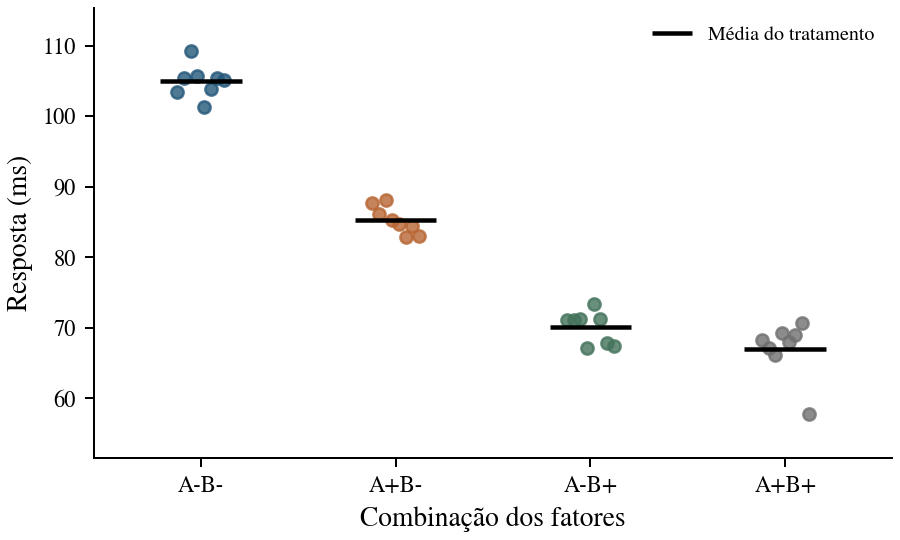

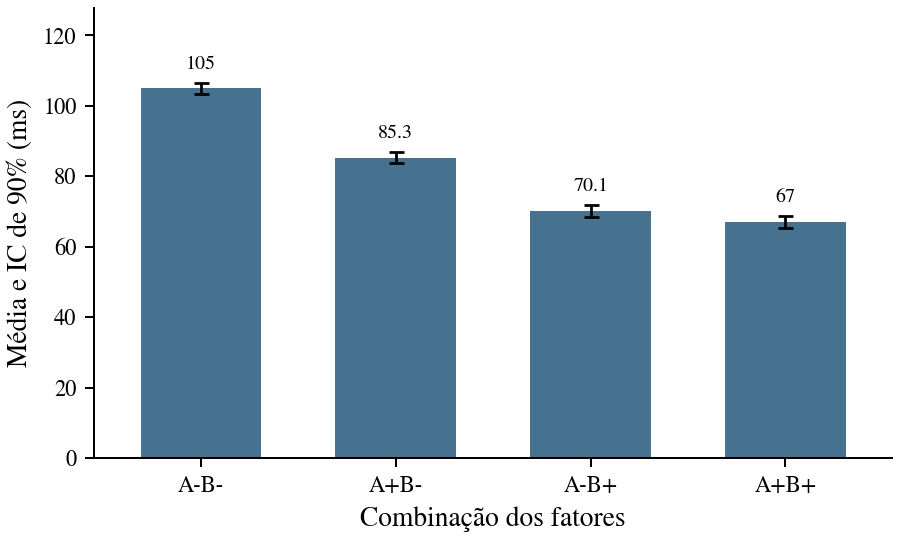

In [ ]:
tabela_combinacoes = graficos_combinacoes(res_api, nomes_api, niveis_api, "api_combinacoes")


### Efeitos e alocação da variação

Os intervalos dos coeficientes permitem comparar cada efeito com zero. O gráfico de variação inclui a parcela de erro. Uma parcela elevada associada ao cache significa que essa mudança explica boa parte da dispersão observada entre as condições ensaiadas. Ela não significa uma redução percentual equivalente da latência.


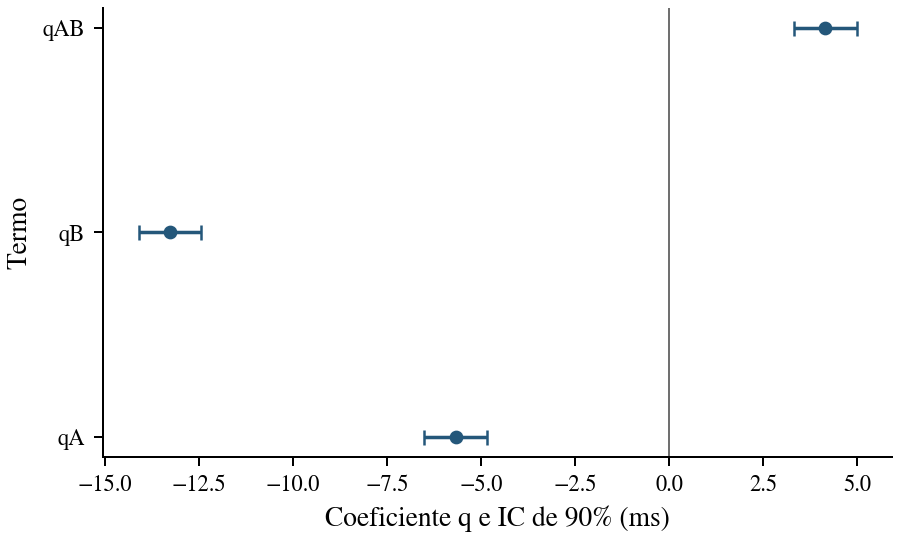

,Fonte,SS,Variação alocada (%)
0,A,1031.8,13.871
1,B,5642.3,75.853
2,AB,552.26,7.4245
3,Erro,212.07,2.851


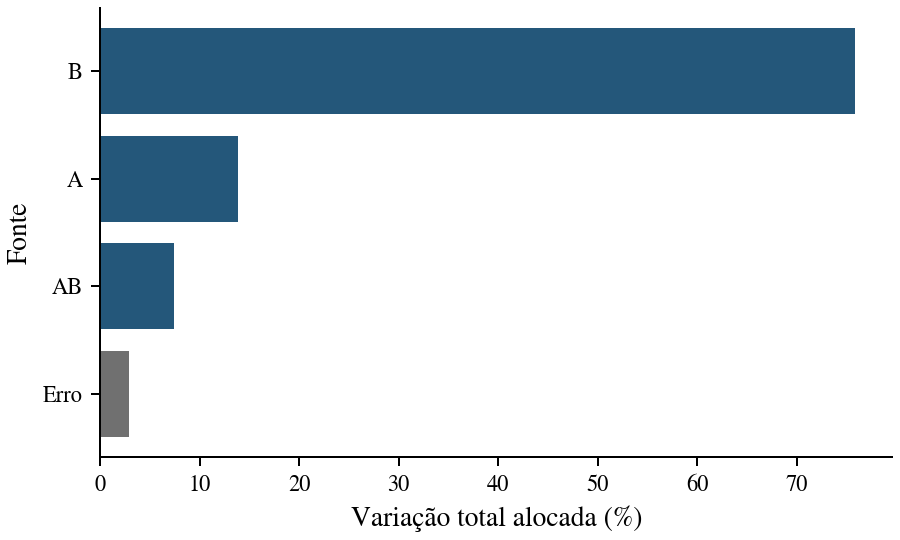

In [ ]:
graficos_efeitos(res_api, "api")
grafico_variacao(res_api, "api")


### Níveis e interação

No grid de níveis, o painel (a) corresponde a workers e o painel (b) ao cache. As médias marginais resumem a mudança de cada fator sobre os dois níveis do outro. No gráfico de interação, compare as inclinações entre os estados do cache para examinar se a mudança de workers é a mesma nas duas condições.


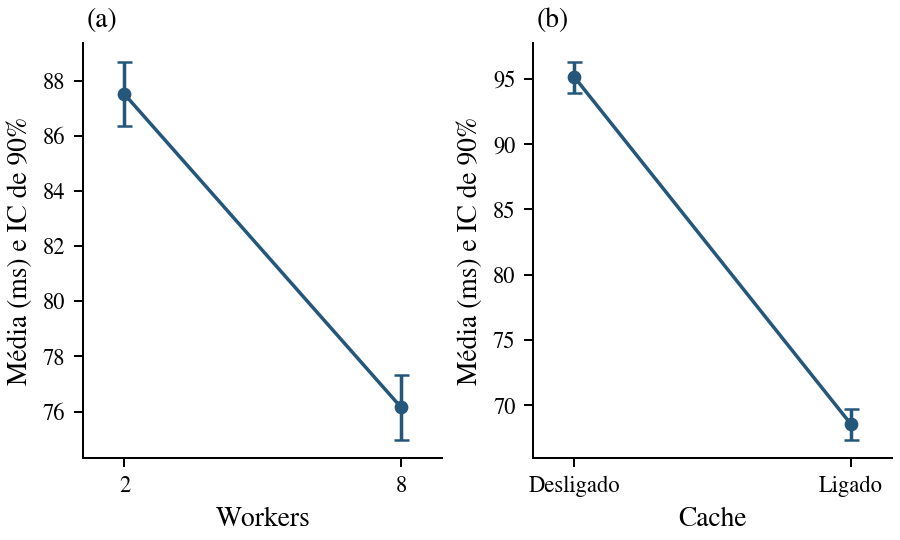

Painéis do gráfico. (a) Workers e Cache. (b) Cache e Workers.

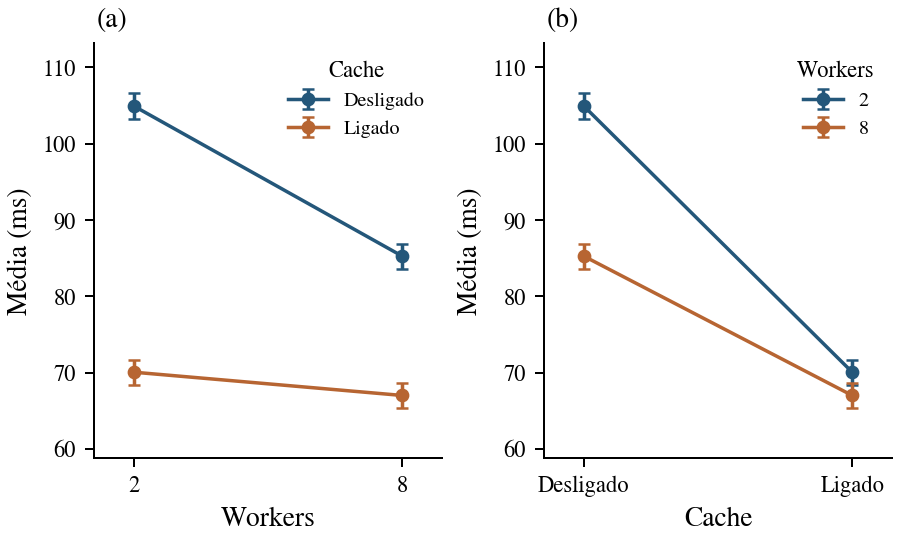

In [ ]:
graficos_niveis(res_api, nomes_api, niveis_api, "api", com_ic=True)
graficos_interacoes(res_api, nomes_api, niveis_api, "api", com_ic=True)


### Resíduos e premissas

O diagnóstico usa os resíduos dentro das quatro combinações e a sequência efetivamente simulada em `ordem_api`. O modelo completo ajusta exatamente quatro médias e não verifica curvatura entre os níveis. A dispersão entre sessões é a fonte de informação sobre o erro experimental.


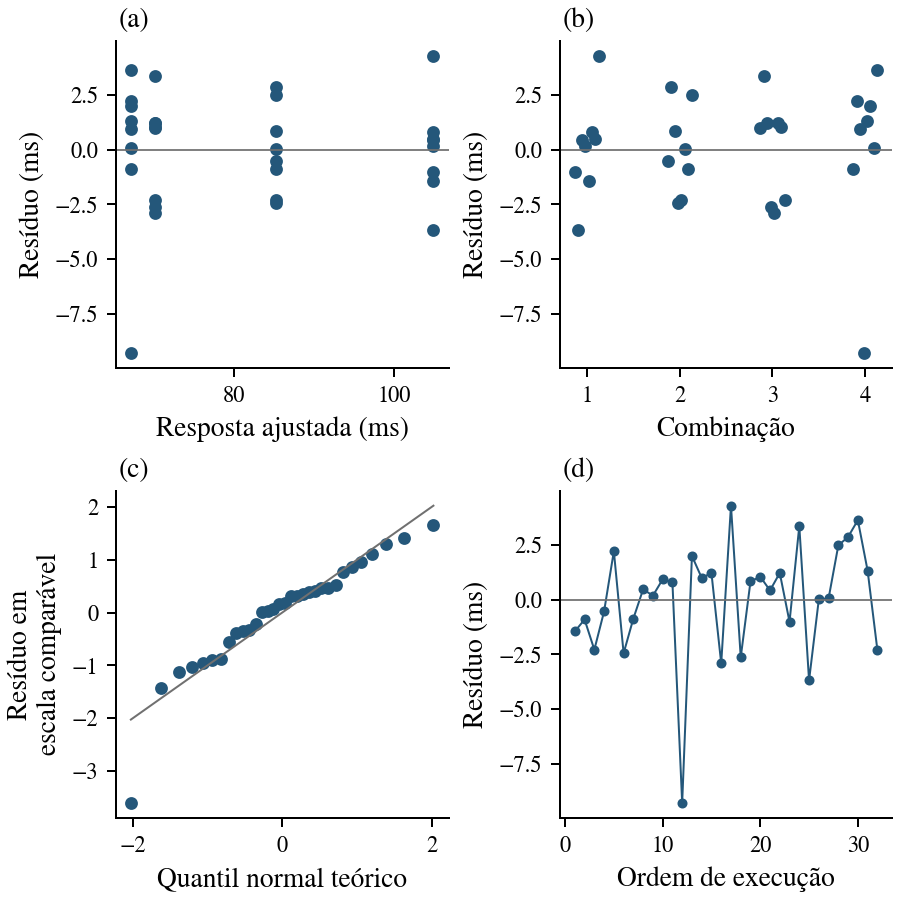

,Diagnóstico,Estatística,Valor-p,Referência
0,Brown e Forsythe,0.23148,0.8737,F aproximada
1,Shapiro e Wilk,0.91101,0.0098,Normal no mesmo desenho
2,Kolmogorov e Smirnov,0.12633,0.2098,Normal no mesmo desenho
3,Durbin e Watson,2.4115,0.2108,Normal independente no mesmo desenho


**Homocedasticidade**

Não é significativo porque o valor-p 0.8737 é maior que 0.10. Não há evidência suficiente contra a igualdade das variâncias.

**Shapiro e Wilk**

É significativo porque o valor-p 0.0098 é menor ou igual a 0.10. Há evidência contra a normalidade dos erros sob a referência adotada.

**Kolmogorov e Smirnov**

Não é significativo porque o valor-p 0.2098 é maior que 0.10. Não há evidência suficiente contra a normalidade sob a referência adotada.

**Durbin e Watson**

Não é significativo porque o valor-p 0.2108 é maior que 0.10. Não há evidência suficiente de dependência serial nessa comparação. O protocolo continua necessário.

In [ ]:
grid_residuos(res_api, ordem_api, "api")
resultados_diagnosticos_api = diagnosticos(res_api, ordem_api, "api")


### Conclusão sobre a API

O efeito de workers precisa ser descrito nas duas condições de cache. Uma redução de latência aparece como uma mudança negativa. A evidência dos testes deve ser lida com os ICs, a magnitude das mudanças e os diagnósticos dos resíduos.


In [ ]:
q_api = res_api["q"]
mudanca_api_sem_cache = 2 * (q_api[1] - q_api[3])
mudanca_api_com_cache = 2 * (q_api[1] + q_api[3])
F_api = ((res_api["SST"] - res_api["SSE"]) / 3) / res_api["MSE"]
p_api = stats.f.sf(F_api, 3, res_api["nu"])
display(Markdown(
    f"A passagem de 2 para 8 workers mudou a latência média em {mudanca_api_sem_cache:.2f} ms "
    f"com cache desligado e {mudanca_api_com_cache:.2f} ms com cache ligado. "
    f"O teste global apresentou F igual a {F_api:.2f} e valor-p de {p_api:.3g}. "
    "As mudanças se referem ao perfil de carga e ao ambiente representados neste caso."
))


A passagem de 2 para 8 workers mudou a latência média em -19.67 ms com cache desligado e -3.05 ms com cache ligado. O teste global apresentou F igual a 318.03 e valor-p de 1e-21. As mudanças se referem ao perfil de carga e ao ambiente representados neste caso.

## 2 Energia de comunicação em IoT

O objetivo é quantificar como protocolo e tamanho de mensagem afetam a energia média por mensagem entregue. A resposta, em milijoules, é a energia total de uma sessão dividida pelo número de mensagens da janela. Cada sessão contém 100 mensagens e constitui uma replicação.

| Fator | Nível baixo | Nível alto | Hipótese substantiva |
| --- | --- | --- | --- |
| $A$ | MQTT com QoS 1 | CoAP confirmável | A diferença de cabeçalhos e de processamento pode alterar a energia por mensagem |
| $B$ | Payload de 128 B | Payload de 1024 B | Mais bytes podem aumentar o custo de transmissão e de processamento |

A hipótese de interação é que a diferença entre os protocolos dependa do payload. Dispositivo, enlace Wi-Fi, distância, segurança, taxa de mensagens e regra de entrega permanecem fixos. Cada sessão reinicia o dispositivo e usa uma realização independente das condições aleatórias do enlace.


In [ ]:
TABELAS = BASE / "tabelas" / NOME_NOTEBOOK / "iot"
TABELAS.mkdir(parents=True, exist_ok=True)
rng_iot = np.random.default_rng(60602)
r_iot = 8
A_iot = np.array([-1, 1, -1, 1])
B_iot = np.array([-1, -1, 1, 1])
Xc_iot = np.column_stack([np.ones(4), A_iot, B_iot, A_iot * B_iot])
q_gerador_iot = np.array([6.0, -0.35, 0.85, -0.25])
ordem_iot = rng_iot.permutation(4 * r_iot)
erros_iot = np.empty(4 * r_iot)
erros_iot[ordem_iot] = rng_iot.normal(0, 0.18, 4 * r_iot)
response_iot = (Xc_iot @ q_gerador_iot)[:, None] + erros_iot.reshape(4, r_iot)
nomes_iot = ["Protocolo", "Payload"]
niveis_iot = [["MQTT", "CoAP"], ["128 B", "1024 B"]]
display(pd.DataFrame(response_iot, index=["A- B-", "A+ B-", "A- B+", "A+ B+"],
                     columns=[f"Replicação {j}" for j in range(1, r_iot + 1)]))


,Replicação 1,Replicação 2,Replicação 3,Replicação 4,Replicação 5,Replicação 6,Replicação 7,Replicação 8
A- B-,5.3006,5.3383,5.232,5.2852,5.1614,5.1232,5.1652,5.0644
A+ B-,5.2345,5.4606,5.2639,4.9568,4.9345,5.1525,4.9646,4.8234
A- B+,7.3793,7.6648,7.662,7.6175,7.4255,7.0928,7.3147,7.1863
A+ B+,6.0416,6.4254,6.4493,6.2789,6.114,6.3792,6.1277,6.2906


### Modelo estimado e inferência

O sinal do efeito de protocolo depende da codificação. Aqui, uma mudança negativa de $A$ representa menor energia média em CoAP em relação a MQTT. A comparação deve continuar condicionada à regra de entrega e às configurações especificadas, pois nomes de protocolos não definem sozinhos toda a comunicação.


In [ ]:
res_iot = ajustar(response_iot)
res_iot["unidade"] = "mJ por mensagem"
modelo_escrito(res_iot, resposta="E")
mostrar_resultados(res_iot)
mostrar_anova(res_iot)


$$\widehat{E}=5.997 - 0.3161x_{A} + 0.8434x_{B} - 0.2612x_{A}x_{B}.$$

,Termo,q,EP de q,IC inferior,IC superior,Efeito 2q,t,Valor-p,Significativo
0,A,-0.31611,0.031366,-0.36947,-0.26276,-0.63223,-10.078,8.099e-11,Sim
1,B,0.84339,0.031366,0.79003,0.89674,1.6868,26.889,1.525e-21,Sim
2,AB,-0.26115,0.031366,-0.31451,-0.20779,-0.5223,-8.326,4.653e-09,Sim


**Efeito qA**

É significativo porque o valor-p 8.099e-11 é menor ou igual a 0.10. Há evidência de que qA difere de zero nas condições do modelo.

**Efeito qB**

É significativo porque o valor-p 1.525e-21 é menor ou igual a 0.10. Há evidência de que qB difere de zero nas condições do modelo.

**Efeito qAB**

É significativo porque o valor-p 4.653e-09 é menor ou igual a 0.10. Há evidência de que qAB difere de zero nas condições do modelo.

,Fonte,SS,gl,MS,F,Valor-p
0,A,3.1977,1,3.1977,101.57,8.099e-11
1,B,22.762,1,22.762,723.01,1.525e-21
2,AB,2.1824,1,2.1824,69.322,4.653e-09
3,Erro,0.88149,28,0.031482,NaN,
4,Total,29.023,31,NaN,NaN,


,F global,gl numerador,gl denominador,Valor-p
0,297.97,3,28,2.428e-21


**Teste F global**

É significativo porque o valor-p 2.428e-21 é menor ou igual a 0.10. Há evidência de que pelo menos um termo do modelo difere de zero.

### Respostas das combinações


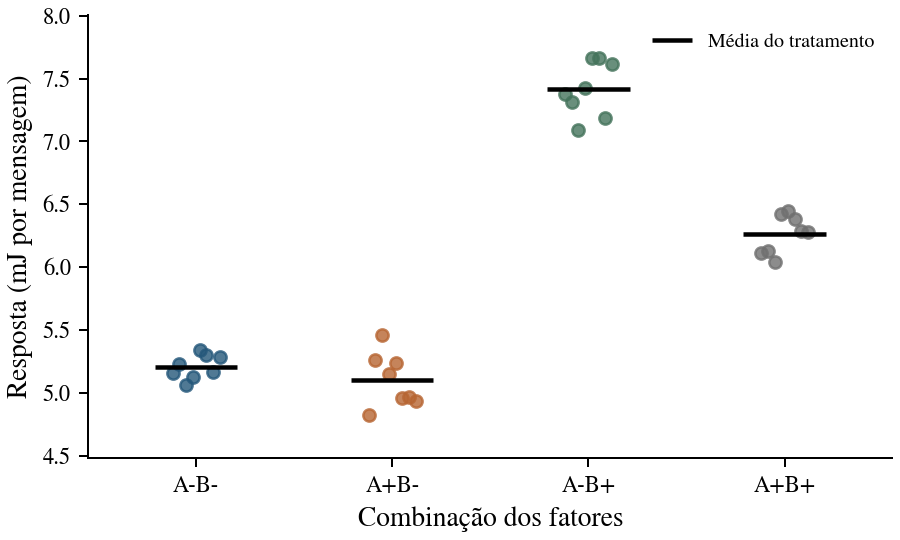

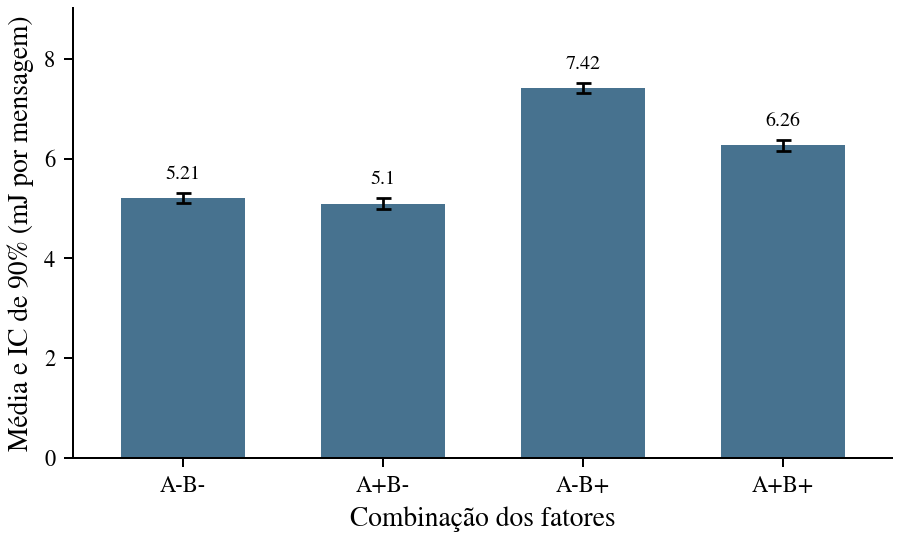

In [ ]:
tabela_combinacoes = graficos_combinacoes(res_iot, nomes_iot, niveis_iot, "iot_combinacoes")


### Efeitos e alocação da variação

A unidade dos coeficientes é milijoule por mensagem. Já a alocação é uma porcentagem da soma de quadrados total desta resposta. As duas escalas respondem a perguntas diferentes e devem ser interpretadas separadamente.


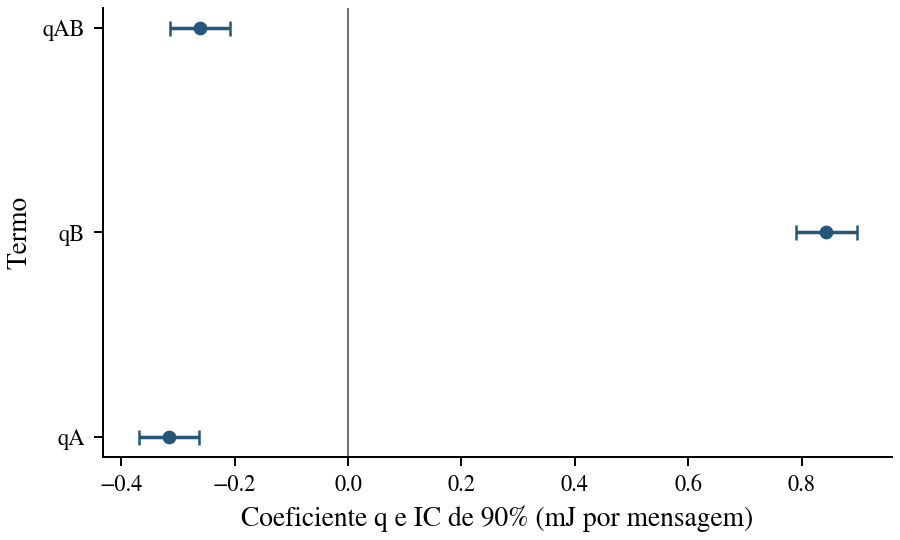

,Fonte,SS,Variação alocada (%)
0,A,3.1977,11.018
1,B,22.762,78.426
2,AB,2.1824,7.5194
3,Erro,0.88149,3.0372


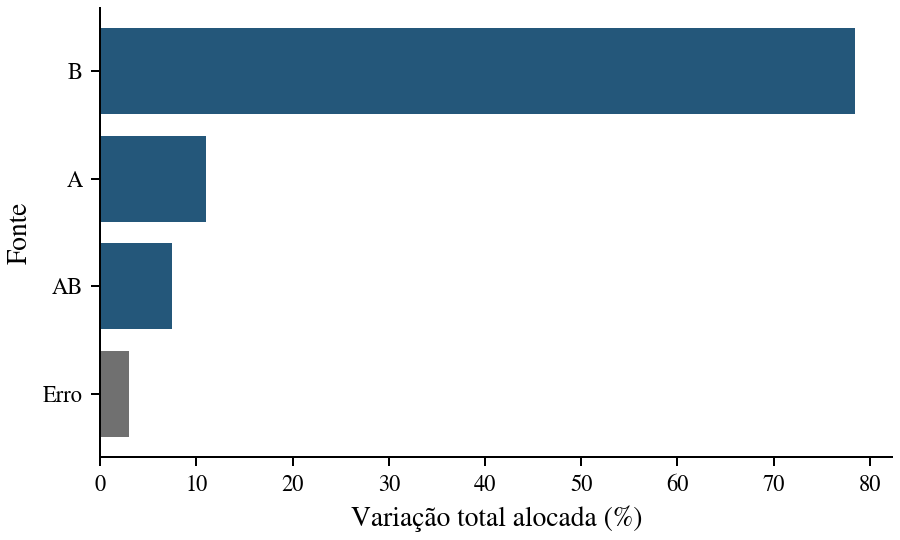

In [ ]:
graficos_efeitos(res_iot, "iot")
grafico_variacao(res_iot, "iot")


### Níveis e interação

No grid de níveis, o painel (a) corresponde ao protocolo e o painel (b) ao payload. O payload tem uma ordem quantitativa, enquanto MQTT e CoAP são categorias. As linhas de interação comparam dois protocolos nos níveis ensaiados e não representam um protocolo intermediário.


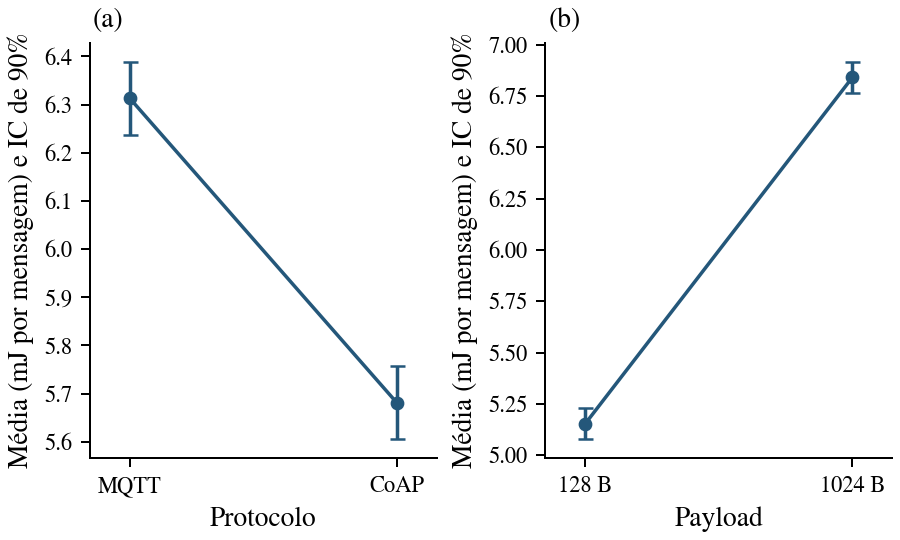

Painéis do gráfico. (a) Protocolo e Payload. (b) Payload e Protocolo.

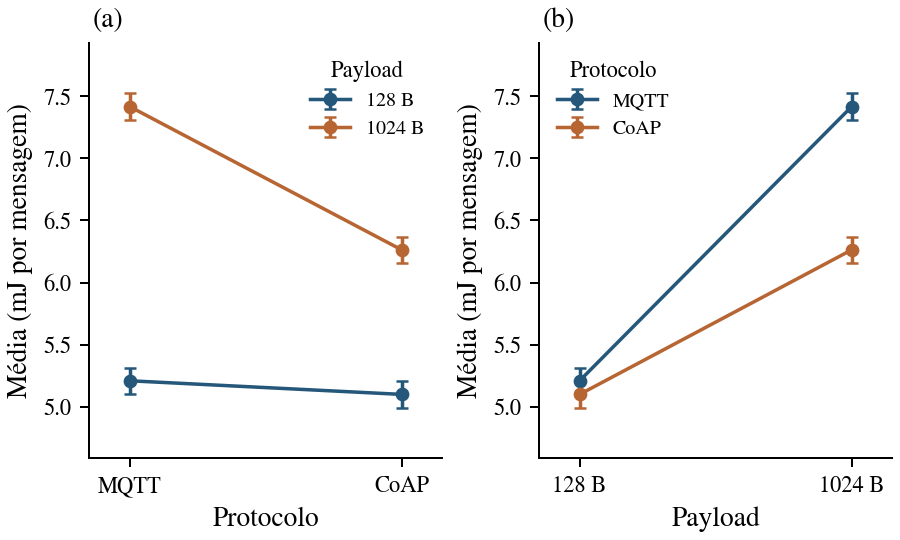

In [ ]:
graficos_niveis(res_iot, nomes_iot, niveis_iot, "iot", com_ic=True)
graficos_interacoes(res_iot, nomes_iot, niveis_iot, "iot", com_ic=True)


### Resíduos e premissas

As 100 mensagens de uma sessão produzem uma única resposta. Tratar essas mensagens como 100 replicações do fatorial subestimaria a incerteza. Os diagnósticos usam as 32 sessões e respeitam `ordem_iot` para examinar a sequência de execução.


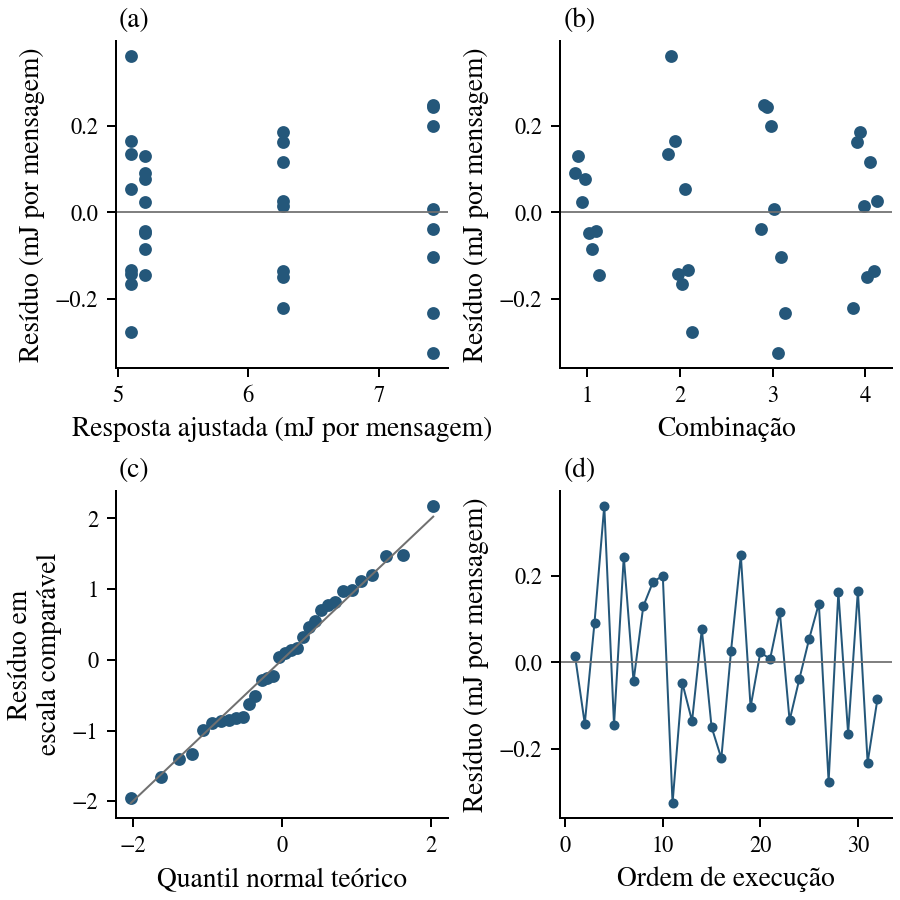

,Diagnóstico,Estatística,Valor-p,Referência
0,Brown e Forsythe,2.152,0.1161,F aproximada
1,Shapiro e Wilk,0.98359,0.8806,Normal no mesmo desenho
2,Kolmogorov e Smirnov,0.099525,0.568,Normal no mesmo desenho
3,Durbin e Watson,2.54,0.1296,Normal independente no mesmo desenho


**Homocedasticidade**

Não é significativo porque o valor-p 0.1161 é maior que 0.10. Não há evidência suficiente contra a igualdade das variâncias.

**Shapiro e Wilk**

Não é significativo porque o valor-p 0.8806 é maior que 0.10. Não há evidência suficiente contra a normalidade sob a referência adotada.

**Kolmogorov e Smirnov**

Não é significativo porque o valor-p 0.568 é maior que 0.10. Não há evidência suficiente contra a normalidade sob a referência adotada.

**Durbin e Watson**

Não é significativo porque o valor-p 0.1296 é maior que 0.10. Não há evidência suficiente de dependência serial nessa comparação. O protocolo continua necessário.

In [ ]:
grid_residuos(res_iot, ordem_iot, "iot")
resultados_diagnosticos_iot = diagnosticos(res_iot, ordem_iot, "iot")


### Conclusão sobre energia

A diferença entre protocolos pode mudar conforme o tamanho da mensagem. Um efeito principal médio não substitui essa leitura condicional. Os resultados descrevem energia por mensagem entregue e não autonomia de bateria, que depende também de componentes do dispositivo ausentes desta resposta.


In [ ]:
q_iot = res_iot["q"]
mudanca_iot_128 = 2 * (q_iot[1] - q_iot[3])
mudanca_iot_1024 = 2 * (q_iot[1] + q_iot[3])
F_iot = ((res_iot["SST"] - res_iot["SSE"]) / 3) / res_iot["MSE"]
p_iot = stats.f.sf(F_iot, 3, res_iot["nu"])
display(Markdown(
    f"A mudança de MQTT para CoAP correspondeu a {mudanca_iot_128:.3f} mJ por mensagem "
    f"com payload de 128 B e a {mudanca_iot_1024:.3f} mJ com payload de 1024 B. "
    f"O teste global apresentou F igual a {F_iot:.2f} e valor-p de {p_iot:.3g}. "
    "A interpretação mantém as condições de enlace e de entrega definidas no caso."
))


A mudança de MQTT para CoAP correspondeu a -0.110 mJ por mensagem com payload de 128 B e a -1.155 mJ com payload de 1024 B. O teste global apresentou F igual a 297.97 e valor-p de 2.43e-21. A interpretação mantém as condições de enlace e de entrega definidas no caso.

## 3 Tempo de treinamento de uma árvore de decisão

O objetivo é quantificar como limite de profundidade e quantidade de dados alteram o tempo de treinamento. A resposta é o tempo de uma sessão de ajuste, em segundos. A implementação da árvore, o número de atributos, a distribuição geradora dos dados e a quantidade de núcleos permanecem fixos.

| Fator | Nível baixo | Nível alto | Hipótese substantiva |
| --- | --- | --- | --- |
| $A$ | Profundidade máxima de 3 | Profundidade máxima de 12 | Árvores mais profundas podem exigir mais operações durante o treinamento |
| $B$ | Mil exemplos de treino | Dez mil exemplos de treino | Mais exemplos podem aumentar o custo de construir a árvore |

A hipótese de interação é que o custo adicional de profundidade seja maior com mais dados. Cada sessão começa em um processo novo e usa uma amostra de treinamento independente. Compartilhar a mesma amostra entre condições criaria dependência e exigiria representar esse desenho na análise.


In [ ]:
TABELAS = BASE / "tabelas" / NOME_NOTEBOOK / "ml"
TABELAS.mkdir(parents=True, exist_ok=True)
rng_ml = np.random.default_rng(60603)
r_ml = 8
A_ml = np.array([-1, 1, -1, 1])
B_ml = np.array([-1, -1, 1, 1])
Xc_ml = np.column_stack([np.ones(4), A_ml, B_ml, A_ml * B_ml])
q_gerador_ml = np.array([4.5, 0.9, 1.5, 0.6])
ordem_ml = rng_ml.permutation(4 * r_ml)
erros_ml = np.empty(4 * r_ml)
erros_ml[ordem_ml] = rng_ml.normal(0, 0.22, 4 * r_ml)
response_ml = (Xc_ml @ q_gerador_ml)[:, None] + erros_ml.reshape(4, r_ml)
nomes_ml = ["Profundidade máxima", "Exemplos de treino"]
niveis_ml = [["3", "12"], ["Mil", "Dez mil"]]
display(pd.DataFrame(response_ml, index=["A- B-", "A+ B-", "A- B+", "A+ B+"],
                     columns=[f"Replicação {j}" for j in range(1, r_ml + 1)]))


,Replicação 1,Replicação 2,Replicação 3,Replicação 4,Replicação 5,Replicação 6,Replicação 7,Replicação 8
A- B-,2.7143,2.5732,2.5615,2.9292,2.764,2.7805,2.9506,2.7143
A+ B-,3.4462,3.29,3.0519,3.3966,3.1959,3.2532,3.2145,3.2343
A- B+,5.0235,4.4076,4.4004,4.4839,4.192,4.5462,4.4751,4.6708
A+ B+,7.4019,7.2527,7.6999,7.454,7.2409,7.3347,7.403,7.4516


### Modelo estimado e inferência

Os coeficientes descrevem o tempo de treinamento nos quatro vértices do planejamento. Um efeito positivo indica aumento de tempo na passagem ao nível alto. O estudo não mede acurácia, generalização ou outra qualidade preditiva da árvore.


In [ ]:
res_ml = ajustar(response_ml)
res_ml["unidade"] = "s"
modelo_escrito(res_ml, resposta="T")
mostrar_resultados(res_ml)
mostrar_anova(res_ml)


$$\widehat{T}=4.485 + 0.8479x_{A} + 1.48x_{B} + 0.592x_{A}x_{B}.$$

,Termo,q,EP de q,IC inferior,IC superior,Efeito 2q,t,Valor-p,Significativo
0,A,0.84795,0.030039,0.79685,0.89904,1.6959,28.229,4.097e-22,Sim
1,B,1.4803,0.030039,1.4292,1.5314,2.9605,49.278,9.396e-29,Sim
2,AB,0.59202,0.030039,0.54092,0.64311,1.184,19.709,5.96e-18,Sim


**Efeito qA**

É significativo porque o valor-p 4.097e-22 é menor ou igual a 0.10. Há evidência de que qA difere de zero nas condições do modelo.

**Efeito qB**

É significativo porque o valor-p 9.396e-29 é menor ou igual a 0.10. Há evidência de que qB difere de zero nas condições do modelo.

**Efeito qAB**

É significativo porque o valor-p 5.96e-18 é menor ou igual a 0.10. Há evidência de que qAB difere de zero nas condições do modelo.

,Fonte,SS,gl,MS,F,Valor-p
0,A,23.008,1,23.008,796.85,4.097e-22
1,B,70.117,1,70.117,2428.4,9.396e-29
2,AB,11.215,1,11.215,388.43,5.96e-18
3,Erro,0.80848,28,0.028874,NaN,
4,Total,105.15,31,NaN,NaN,


,F global,gl numerador,gl denominador,Valor-p
0,1204.5,3,28,1.09e-29


**Teste F global**

É significativo porque o valor-p 1.09e-29 é menor ou igual a 0.10. Há evidência de que pelo menos um termo do modelo difere de zero.

### Respostas das combinações


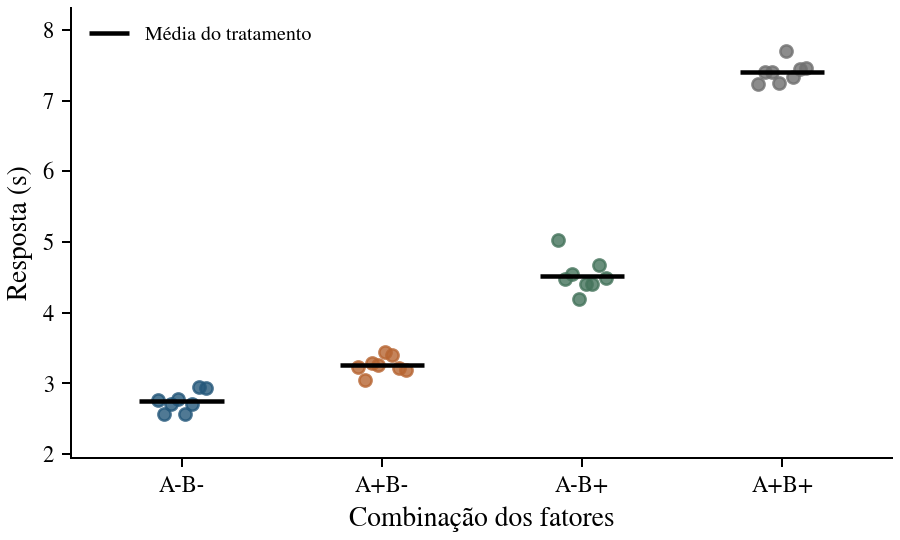

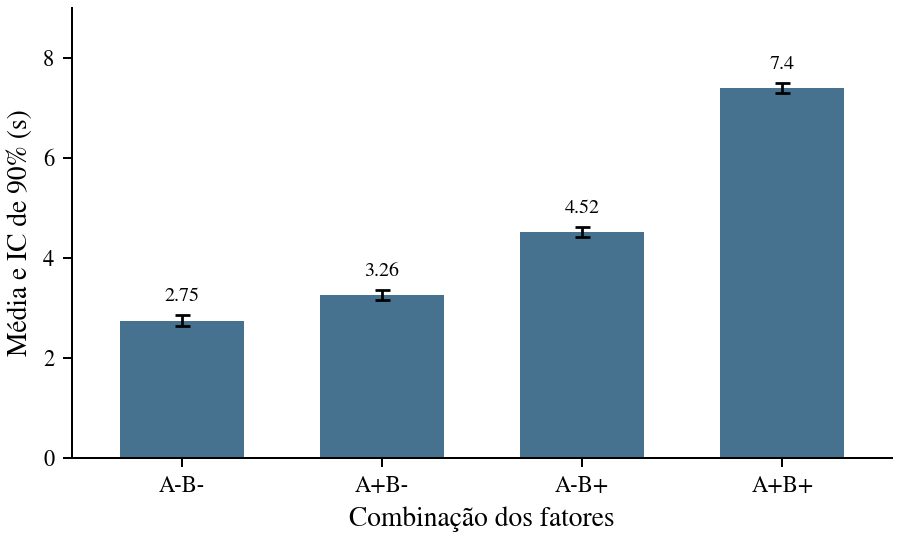

In [ ]:
tabela_combinacoes = graficos_combinacoes(res_ml, nomes_ml, niveis_ml, "ml_combinacoes")


### Efeitos e alocação da variação

A importância relativa dos termos é calculada para tempo de treinamento. Um resultado sobre essa resposta não se transfere automaticamente para acurácia ou consumo de memória. A parcela de erro descreve a variabilidade residual das sessões simuladas.


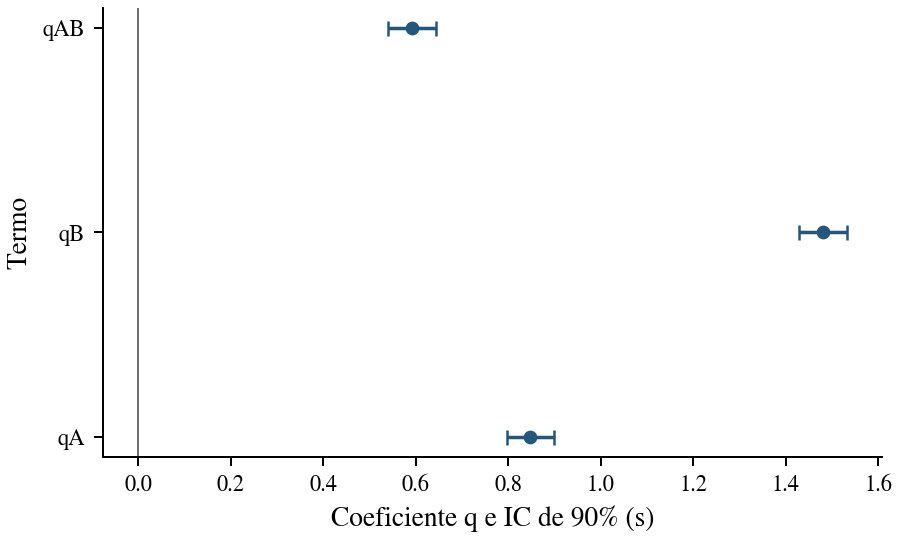

,Fonte,SS,Variação alocada (%)
0,A,23.008,21.882
1,B,70.117,66.683
2,AB,11.215,10.666
3,Erro,0.80848,0.76889


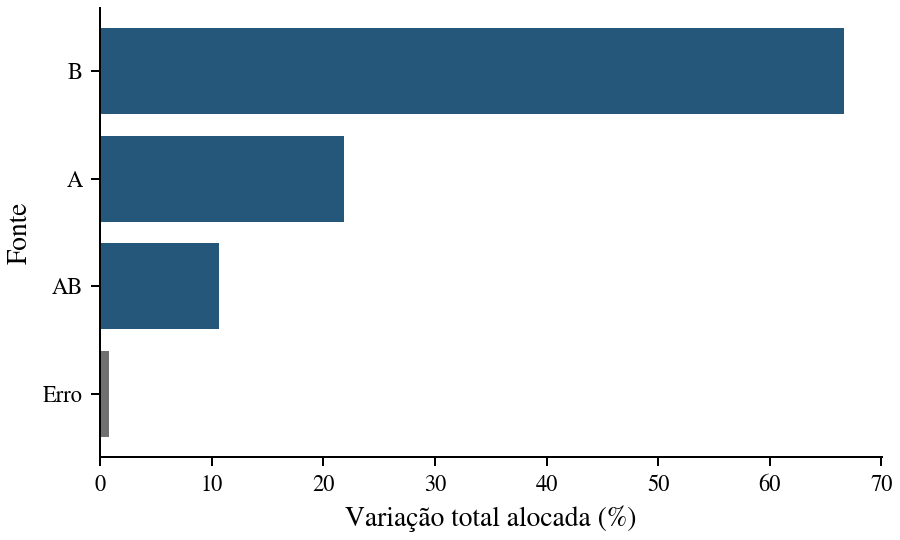

In [ ]:
graficos_efeitos(res_ml, "ml")
grafico_variacao(res_ml, "ml")


### Níveis e interação

No grid de níveis, o painel (a) corresponde à profundidade e o painel (b) à quantidade de exemplos. A interação compara quanto a mudança de profundidade altera o tempo com mil e com dez mil exemplos. Somente esses níveis foram representados no planejamento.


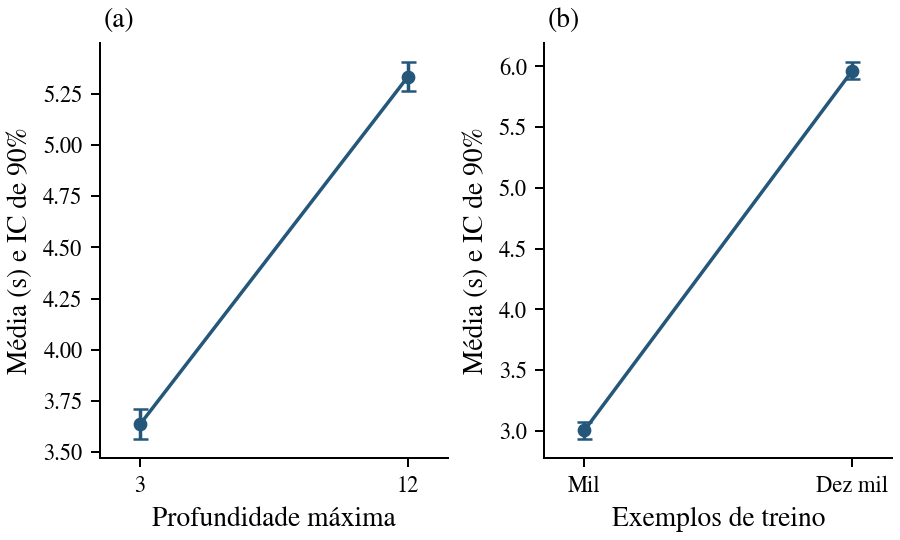

Painéis do gráfico. (a) Profundidade máxima e Exemplos de treino. (b) Exemplos de treino e Profundidade máxima.

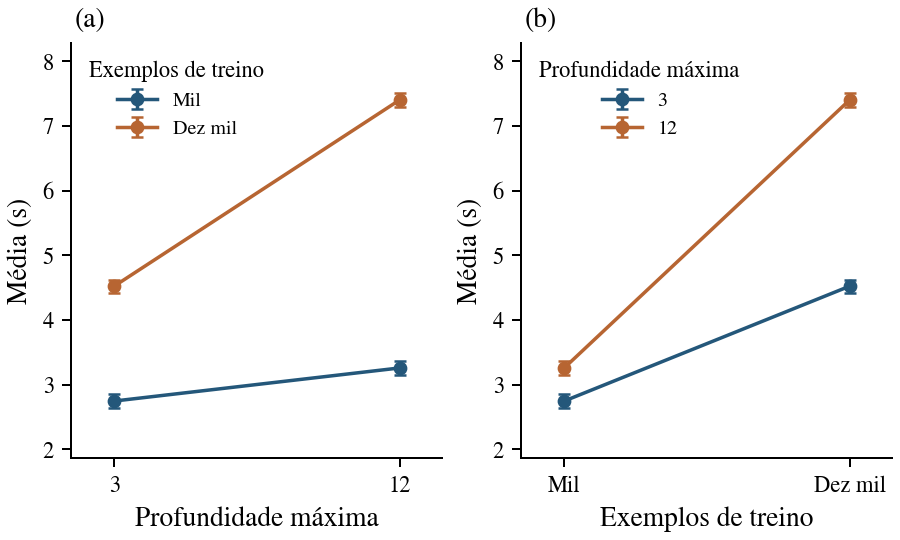

In [ ]:
graficos_niveis(res_ml, nomes_ml, niveis_ml, "ml", com_ic=True)
graficos_interacoes(res_ml, nomes_ml, niveis_ml, "ml", com_ic=True)


### Resíduos e premissas

A variação entre sessões pode representar amostras de treino independentes e pequenas flutuações de execução. Na geração artificial, os erros foram produzidos em ordem temporal e depois organizados por combinação. `ordem_ml` recupera essa sequência para o diagnóstico de independência.


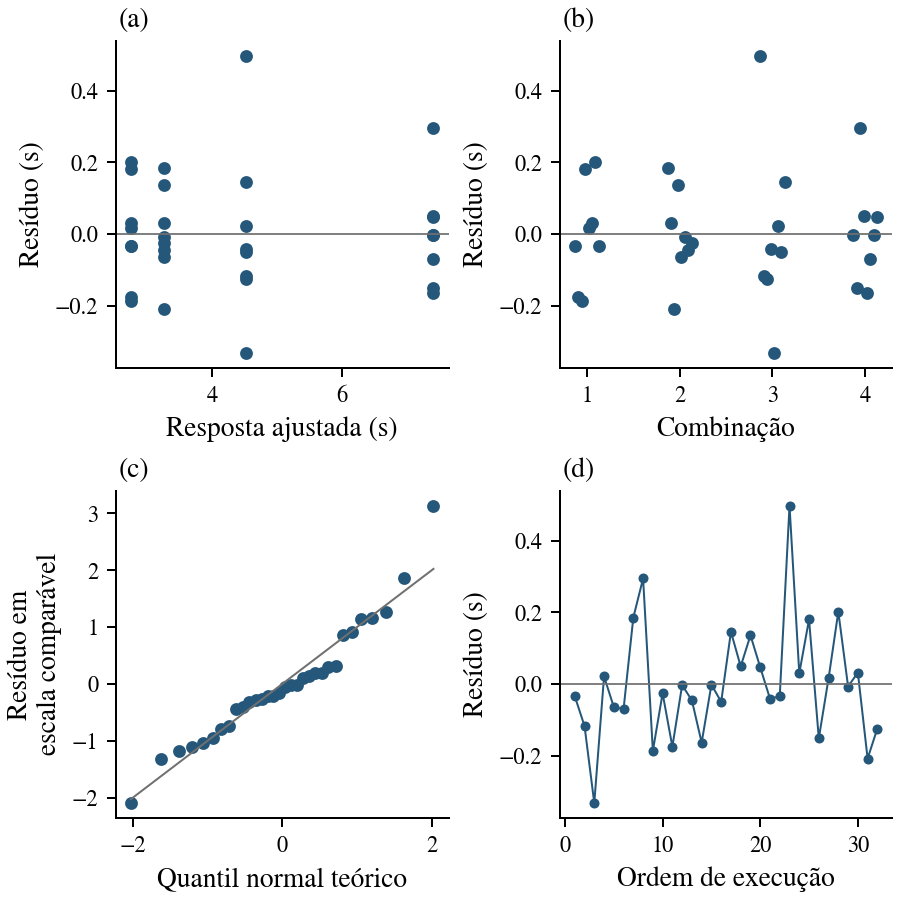

,Diagnóstico,Estatística,Valor-p,Referência
0,Brown e Forsythe,0.52577,0.6682,F aproximada
1,Shapiro e Wilk,0.9474,0.1258,Normal no mesmo desenho
2,Kolmogorov e Smirnov,0.16158,0.028,Normal no mesmo desenho
3,Durbin e Watson,1.8549,0.708,Normal independente no mesmo desenho


**Homocedasticidade**

Não é significativo porque o valor-p 0.6682 é maior que 0.10. Não há evidência suficiente contra a igualdade das variâncias.

**Shapiro e Wilk**

Não é significativo porque o valor-p 0.1258 é maior que 0.10. Não há evidência suficiente contra a normalidade sob a referência adotada.

**Kolmogorov e Smirnov**

É significativo porque o valor-p 0.028 é menor ou igual a 0.10. Há evidência contra a normalidade dos erros sob a referência adotada.

**Durbin e Watson**

Não é significativo porque o valor-p 0.708 é maior que 0.10. Não há evidência suficiente de dependência serial nessa comparação. O protocolo continua necessário.

In [ ]:
grid_residuos(res_ml, ordem_ml, "ml")
resultados_diagnosticos_ml = diagnosticos(res_ml, ordem_ml, "ml")


### Conclusão sobre tempo de treinamento

A magnitude da mudança de profundidade precisa acompanhar o tamanho do conjunto de treinamento. Uma interação positiva indica que esse aumento de tempo é maior no nível alto de dados. O alcance permanece restrito à distribuição, à implementação e aos recursos representados no caso.


In [1]:
q_ml = res_ml["q"]
mudanca_ml_mil = 2 * (q_ml[1] - q_ml[3])
mudanca_ml_dez_mil = 2 * (q_ml[1] + q_ml[3])
F_ml = ((res_ml["SST"] - res_ml["SSE"]) / 3) / res_ml["MSE"]
p_ml = stats.f.sf(F_ml, 3, res_ml["nu"])
display(Markdown(
    f"A passagem da profundidade máxima de 3 para 12 alterou o tempo médio em {mudanca_ml_mil:.3f} s "
    f"com mil exemplos e em {mudanca_ml_dez_mil:.3f} s com dez mil exemplos. "
    f"O teste global apresentou F igual a {F_ml:.2f} e valor-p de {p_ml:.3g}. "
    "Essas estimativas descrevem custo de treinamento e não qualidade preditiva."
))


NameError: name 'res_ml' is not defined

## Referências

- Aula de Projeto e Análise de Experimentos. Material da disciplina.
- Raj Jain. *The Art of Computer Systems Performance Analysis*. Wiley, 1991. Capítulos 16 a 18. [Material do autor](https://www.cse.wustl.edu/~jain/books/perf_sli.htm) e [errata](https://www.cse.wustl.edu/~jain/books/ftp/errors_all.pdf).
- Douglas C. Montgomery. *Design and Analysis of Experiments*. Planejamento fatorial, análise de variância e adequação de modelos. [Sumário da editora](https://bcs.wiley.com/he-bcs/Books?action=contents&bcsId=11447&itemId=1119492440).
- NIST/SEMATECH. [Delineamentos fatoriais de dois níveis](https://www.itl.nist.gov/div898/handbook/pri/section3/pri3331.htm), [intervalos para a média](https://www.itl.nist.gov/div898/handbook/eda/section3/eda352.htm) e [Levene](https://www.itl.nist.gov/div898/handbook/eda/section3/eda35a.htm).
- SciPy. [Shapiro e Wilk](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.shapiro.html). Statsmodels. [Lilliefors](https://www.statsmodels.org/stable/generated/statsmodels.stats.diagnostic.lilliefors.html) e [Durbin e Watson](https://www.statsmodels.org/stable/generated/statsmodels.stats.stattools.durbin_watson.html). SciPy. [Calibração Monte Carlo com parâmetros estimados](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.goodness_of_fit.html). Referências de implementação dos diagnósticos.
